# Simulations
In this Notebook, I focus on the analysis of the previously reconstructed and curated metabolic models. The individual models are part of the analyses but additionally a community model is reconstructed with MICOM.

To make the models easier to handle in a programming context, they were given the following abbreviations: \
Sma - AA1 \
Bpi - AA2 \
Cpu - AA3 \
Elu - AA4 \
Cin - AA5 \
Hro - AA6 \
Ppu - AA7

## Imports & load models

In [1]:
# basics
import os
import copy
from itertools import product
from collections import Counter

# my own functions
from functions import *

# cobra & micom
from cobra.io import read_sbml_model
from cobra.flux_analysis import pfba, flux_variability_analysis
from cobra.exceptions import Infeasible
from micom import Community

# plot
import matplotlib.pyplot as plt
import seaborn as sns
import holoviews as hv
from holoviews import opts, dim
import plotly.express as px
import plotly.graph_objects as go

In [2]:
# Load SBML Models
models_path = "../Models/02_afterCuration/"
models = {}
for model_name in (f for f in os.listdir(models_path) if f.endswith(".xml")):
    model = read_sbml_model(f"{models_path}/{model_name}")
    model.solver = "cplex"
    name = str(model_name[:3])
    models[name] = model

models = {key: models[key] for key in sorted(models.keys())}  # sorts the dictionary alphabetically
AA1, AA2, AA3, AA4, AA5, AA6, AA7 = [models[f"AA{i}"] for i in range(1, 8)]

In [3]:
get_basic_amounts(models)

AA1 has 2263 reactions and 1513 metabolites
AA2 has 2671 reactions and 1792 metabolites
AA3 has 2218 reactions and 1498 metabolites
AA4 has 2795 reactions and 1757 metabolites
AA5 has 2106 reactions and 1444 metabolites
AA6 has 2580 reactions and 1687 metabolites
AA7 has 2526 reactions and 1658 metabolites
Mean number of reactions: 2451.285714285714
Mean number of metabolites: 1621.2857142857142


## Functions
Also see functions.py

In [3]:
# functions for manipulation reaction bounds
def change_med_bounds_with_simu(model, new_bound, medium=None):
    old_bound = [model.reactions.get_by_id(rxn.id).lower_bound for rxn in model.reactions if rxn.id.startswith("EX_")]
    print(f"growth rate in complete medium: ", pfba(model).fluxes["Growth"])
    with model:

        try:
            if medium is None:
                for rxn in model.medium.keys():
                    model.reactions.get_by_id(rxn).lower_bound = -new_bound
                print(f"growth rate with new bounds (-{new_bound}): ", pfba(model).fluxes["Growth"])
            else:
                if isinstance(medium, pd.DataFrame):
                    medium = dict(zip(medium.reaction, medium.bound))

                new_med = {x: new_bound for x in medium}

                growth_val = test_medium(model, new_med)
                print(f"growth rate with new bounds (-{new_bound}): ", growth_val)
        except Infeasible:
            print(f"growth rate with new bounds (-{new_bound}): Infeasible")


In [4]:
def change_medium_bounds(medium_df, carbon_bound, non_carbon_bound=1000):
    if not isinstance(medium_df, pd.DataFrame):
        return "please df :c"

    medium_df = medium_df.copy()

    medium_df["bound"] = np.where(
    medium_df["reaction"].isin(m9_rxn),
        non_carbon_bound,   # value if reaction is in m9_rxn
        carbon_bound)       # value if not

    return medium_df

In [5]:
def uptakes_pfba(model):
    model_pfba = model.summary()
    print("Growth:", pfba(model).fluxes["Growth"])
    return model_pfba.uptake_flux

In [6]:
def check_B_vitamins(model):
    metabos = model.metabolites

    # Convert model metabolite IDs to base names (without compartment suffixes)
    model_mets = {met.id.rsplit('_', 1)[0] for met in metabos}

    # Track which B vitamins are missing
    missing_vitamins = []

    for Bname, vit_mets in Bvitamins.items():
        if not any(vit in model_mets for vit in vit_mets):
            missing_vitamins.append(Bname)

    if missing_vitamins:
        print(model.id, "- Missing B vitamins in:", ', '.join(missing_vitamins))
    else:
        print(model.id, "- All B vitamins are present.")

In [7]:
def secreted_mets_for_crossfeed(model, m9_df, carbon_list, fva = False):
    # check carbon sources first
    if not all(carbon.startswith("EX") for carbon in carbon_list):
        raise ValueError("Please give the Exchange reaction for all carbon sources, e.g. 'EX_sucr_e'")

    # create medium with M9 and carbon source (this should only be one but it is already written so it could take multiple carbon sources)
    carbon_df = pd.DataFrame({
    "reaction": carbon_list,
    "bound": [10] * len(carbon_list)  # repeat 10 for each entry
    })

    # Concatenate to get new medium
    medium = pd.concat([m9_df, carbon_df], ignore_index=True)
    #print(medium)

    # doing pFBA or FVA
    min_val = 1e-6 # fluxes have to be above certain threshold to be considered secretion
    if not fva:
        fluxes = get_pfba_fluxes(model, medium)
        secreted = fluxes[(fluxes > min_val) & (fluxes.index.str.startswith("EX_"))]
        secreted_dict = secreted.to_dict()
    else:
        change_medium(model, medium)
        fluxies = flux_variability_analysis(model, fraction_of_optimum=0.98, pfba_factor=1.05)
        secreted = fluxies[fluxies.index.str.startswith("EX_") & (fluxies["minimum"] >= 0) & (fluxies["maximum"] > min_val)]
        #secreted_dict = secreted[['maximum', 'minimum']].mean(axis=1).to_dict()
        secreted_dict = secreted[['maximum', 'minimum']].mean(axis=1).clip(upper=10).to_dict() # this makes average but if it is above 10 then set it to 10

    return secreted_dict

In [8]:
def cross_feed(model, m9_df, supernatant, fixed_bound = None):
    # supernatant is the return of secreted_mets_for_crossfeed

    # turn secreted dict into df
    supernatant = pd.DataFrame(list(supernatant.items()), columns=["reaction", "bound"])

    if fixed_bound is not None: # have the option to set uptake bound yourself
        supernatant["bound"] = fixed_bound

    # combine with m9
    whole_medium = pd.concat([m9_df, supernatant], ignore_index=True)

    growth_val = test_medium(model, whole_medium)

    return growth_val

In [9]:
def met_name(models, rxn_id):
    for model in models.values():
        if rxn_id in model.reactions:
            met = list(model.reactions.get_by_id(rxn_id).metabolites.keys())[0].name
            return met
    return "Not in models"

In [10]:
def whole_cross_feeding(models, donors, possible_carbons, m9_df, fixed_bound = None, fva=False, return_df = False):
    # Collect results (growth) in a dict of dicts
    results = {}

    for carbon in possible_carbons:
        if len(carbon) > 10: # arbitrary number
            carbon_name = "MRE"
        else:
            carbon_name = met_name(models, carbon[0])
        for donor in donors:
            row_name = f"{carbon_name} & {donor}"
            results[row_name] = {}

            # simulate secretion
            if donor != "Fresh":
                secretion = secreted_mets_for_crossfeed(models[donor], m9_df, carbon, fva)

            # test each recipient
            for recip in models.values():
                if donor != "Fresh":
                    #print(donor, carbon, secretion)
                    #print(secretion)
                    growth = cross_feed(recip, m9_df, secretion, fixed_bound)
                else: # Fresh aka no cross-feeding yet
                    carbon_dict = {key: 10 for key in carbon}
                    #print(carbon_dict)
                    growth = cross_feed(recip, m9_df, carbon_dict, fixed_bound)

                results[row_name][recip.id] = growth

    # Convert to dataframe
    df_results = pd.DataFrame(results).T  # rows=conditions, cols=models

    ######### Plot #########
    plt.figure(figsize=(10, 8))
    ax = sns.heatmap(
        df_results, annot=True, cmap="YlOrRd", fmt=".2f",
        cbar_kws={"label": "Growth\n[mmol/(gDW h)]", "orientation":"vertical"}
    )

    # Access and move colorbar
    cbar = ax.collections[0].colorbar
    cbar.ax.set_position([0.87, 0.1, 0.03, 0.8])  # [x, y, width, height]


    # Left y-axis labels
    left_labels = []
    for c in possible_carbons:
        if len(c) > 10: # arbitrary number
            met = "MRE"
        else:
            met = met_name(models, c[0])   # translate reaction ID -> metabolite name
        left_labels.extend([met] * len(donors))
    ax.set_yticks(np.arange(len(left_labels)) + 0.5)
    ax.set_yticklabels(left_labels, rotation=0)
    ax.set_ylabel("Carbon Source for Donor Strain Growth")

    # Right y-axis labels
    right_labels = [d if d == "Fresh" else models[d].id for d in donors] * len(possible_carbons)
    ax_right = ax.twinx()
    ax_right.set_ylim(ax.get_ylim())
    ax_right.set_ylabel("Medium for Recipient")

    # Remove automatic ticks/grid
    ax_right.yaxis.set_ticks([])
    ax_right.grid(False)

    ax_right.set_yticks(np.arange(len(right_labels)) + 0.5)
    ax_right.set_yticklabels(right_labels, rotation=0)


    for i in range(len(donors), len(donors)*len(possible_carbons)+1, len(donors)):  # add horizontal lines
        plt.hlines(i, *plt.xlim(), color='black', linewidth=1)
    ax.set_xlabel("Recipient Strain")
    plt.title("Cross-feeding")
    plt.show()

    if return_df:
        return df_results
    return None

In [11]:
def split_rxn_id(rxn_id):
    """Split into metabolite part and strain ID."""
    met, strain = rxn_id.rsplit("__", 1) # splitting starts from the right
    return met, strain

In [12]:
def custom_format(x):
    if round(x,1) == 0:
        return "0"          # no decimals for 0
    else:
        return f"{x:.1f}"   # 2 decimals otherwise

In [13]:
def get_V8_medium(base_medium, vitamin_list):
    vitamin_med_V8 = base_medium.copy()

    # Make new rows
    new_rows = pd.DataFrame({
        "reaction": vitamin_list,
        "bound": [10] * len(vitamin_list)
    })

    # Concatenate
    vitamin_med_V8 = pd.concat([vitamin_med_V8, new_rows], ignore_index=True)
    return vitamin_med_V8

In [14]:
# Compare V0 and V8
def vitamin_growth_plots(models, maize_medium, vitamin_list, save_path=None, return_df=False):
    V8_medium = get_V8_medium(maize_medium, vitamin_list)

    # check if models is dict or rather if we have a singular model (which is a community model)
    if not isinstance(models, dict) and not hasattr(models, "__len__"):
        models = {"Community": models}

    results = []
    for model in models.values():
        growth_V0 = test_medium(model, maize_medium)
        growth_V8 = test_medium(model, V8_medium)

        if len(models) == 1 and isinstance(growth_V0, pd.Series): # we have only the community model and wanna see growth of the individual models within the community
            model_ids = growth_V0.index.tolist()
            growth_V0 = growth_V0.values.tolist()
            growth_V8 = growth_V8.values.tolist()
            break

        if isinstance(growth_V0, pd.Series): # make the average for the community model to plot only one value
            growth_V0 = sum(growth_V0)/len(growth_V0)
            growth_V8 = sum(growth_V8)/len(growth_V8)

        # if none of the above if statements are true then we have a normal case with only individual models
        results.append((model.id, growth_V0, growth_V8))

    if return_df:
            df = pd.DataFrame(
                results,
                columns=["model_id", "growth_V0", "growth_V8"]
            )
            df["model_id"] = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"]
            return df

    # Convert to arrays
    if results: # if list is not empty (in case we have only a community model, these are already assigned)
        model_ids = [r[0] for r in results]
        growth_V0 = [r[1] for r in results]
        growth_V8 = [r[2] for r in results]


    # Set up positions
    x = np.arange(len(model_ids))
    width = 0.43  # width of bars

    sns.set_theme(style="whitegrid", rc={"figure.figsize": (10, 5)})  # white background + light gray grid

    fig, ax = plt.subplots()

    # Two bar groups
    bars1 = ax.bar(x - width/2, growth_V0, width, label="V0 (No B-Vitamins)", color="lemonchiffon")
    bars2 = ax.bar(x + width/2, growth_V8, width, label="V8 (Full B-Vitamin Mix)", color="cornflowerblue")

    # Add labels and formatting
    ax.set_ylabel("growth rate\n[mmol/(gDW h)]")
    ax.set_xlabel("Strains")
    if len(models) == 1:
        ax.set_xlabel("Strains within the Community Model")
    ax.set_title("Growth comparison with and without all B vitamins")
    ax.set_xticks(x)
    strain_codes = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"] # this is the same if we use only individual models or only the community model and then look at the strains within
    if len(model_ids) == 8:
        strain_codes = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu", "C7"]
    ax.set_xticklabels(strain_codes, rotation=45)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

    # annotate bars with values
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f"{height:.2f}",
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha="center", va="bottom", fontsize=8)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path)

    plt.show()

In [15]:
# Plot V1 & V7 Experiments
def plot_v1_v7_growth(model, growth_val_without, growth_val_v8, growth_vals_vx, vitamins, mode, save_path=None):

    # Combine all values
    all_growth = [growth_val_without, growth_val_v8] + growth_vals_vx

    # Numeric positions for bars
    x = np.arange(len(all_growth))

    # Create barplot
    plt.figure(figsize=(10, 6))
    """ This is coloring like in Krumbach
    if mode == "V1":
        bars = plt.bar(x, all_growth, color=["lemonchiffon"])
    elif mode =="V7":
        bars = plt.bar(x, all_growth, color=["cornflowerblue"])
        vitamins = [f"V7 (-{vit})" for vit in vitamins]
    else:
        raise ValueError("mode must be either 'V1' or 'V7'")
    """

    # Choose bar colors
    if mode == "V1":
        # pastel color for V1 bars
        pastel_color = "mistyrose"
    elif mode =="V7":
        # pastel color for V7 bars
        pastel_color = "lightblue"
        # update labels for vitamins
        vitamins = [f"V7 (-{vit})" for vit in vitamins]
    else:
        raise ValueError("mode must be either 'V1' or 'V7'")

    # First two bars fixed colors, rest get pastel
    colors = ["lemonchiffon", "cornflowerblue"] + [pastel_color] * len(vitamins)
    bars = plt.bar(x, all_growth, color=colors)

    # Labeling
    plt.ylabel("growth rate\n[mmol/(gDW h)]")
    plt.xlabel("Added B Vitamins")
    plt.title(f"{mode} Experiments: Growth under different media conditions for {model.id}")

    # Add values on top of bars
    for i, bar in enumerate(bars):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, height, f"{height:.2f}",
                 ha="center", va="bottom", fontsize=8)

    # Set x-axis labels properly under each bar
    all_labels = ["V0", "V8"] + vitamins
    plt.xticks(x, all_labels, rotation=45, ha='right')
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path)

    plt.show()


# V1 Experiments
def get_v1_growth(model, mode, list_carbon_source, list_of_vitamins, extra_vitamin_names=None, save_path=None, return_df=False):
    # add single carbon source to minimal media
    carbon_sources = pd.DataFrame({"reaction": list_carbon_source, "bound": [10]*len(list_carbon_source)})
    basic_med = pd.concat([m9, carbon_sources], ignore_index=True)

    # Full vitamin medium (V8)
    med_V8 = get_V8_medium(basic_med, list_of_vitamins)

    with model:
        growth_val_without = test_medium(model, basic_med) # V0
        growth_val_v8 = test_medium(model, med_V8) # V8

    growth_vals_v1 = []
    vitamin_names = []
    for vitamin in list_of_vitamins: # go through list of EX reactions
        vitamin_name = list(model.reactions.get_by_id(vitamin).metabolites.keys())[0].name if vitamin in model.reactions else vitamin
        vitamin_names.append(vitamin_name)

        vitamin_med = basic_med.copy()

        new_row = pd.DataFrame([{"reaction": vitamin, "bound": 10}])
        vitamin_med = pd.concat([vitamin_med, new_row], ignore_index=True)

        with model:
            growth_val_v1 = test_medium(model, vitamin_med)
            growth_vals_v1.append(growth_val_v1)

    if extra_vitamin_names is not None:
        plot_v1_v7_growth(model, growth_val_without, growth_val_v8, growth_vals_v1, extra_vitamin_names, mode, save_path, return_df)
    else:
        plot_v1_v7_growth(model, growth_val_without, growth_val_v8, growth_vals_v1, vitamin_names, mode, save_path, return_df)

In [16]:
# V7 Experiments
def get_v7_growth(model, mode, list_carbon_source, list_of_vitamins, extra_vitamin_names=None, save_path=None):
    # Add single carbon source to minimal media
    carbon_sources = pd.DataFrame({"reaction": list_carbon_source, "bound": [10]*len(list_carbon_source)})
    basic_med = pd.concat([m9, carbon_sources], ignore_index=True)

    # Full vitamin medium (V8)
    med_V8 = get_V8_medium(basic_med, list_of_vitamins)

    with model:
        growth_val_without = test_medium(model, basic_med)  # basic medium
        growth_val_v8 = test_medium(model, med_V8)          # all vitamins

    growth_vals_drop = []
    dropped_vitamin_names = []

    # Drop one vitamin at a time
    for vitamin in list_of_vitamins:
        # Medium with all vitamins except the current one
        vitamin_med = med_V8[~med_V8['reaction'].isin([vitamin])].copy()

        # Get human-readable vitamin name
        vitamin_name = list(model.reactions.get_by_id(vitamin).metabolites.keys())[0].name \
                       if vitamin in model.reactions else vitamin
        dropped_vitamin_names.append(vitamin_name)

        with model:
            growth_val = test_medium(model, vitamin_med)
            growth_vals_drop.append(growth_val)

    # Plot
    if extra_vitamin_names is not None:
        plot_v1_v7_growth(model, growth_val_without, growth_val_v8, growth_vals_drop, extra_vitamin_names, mode, save_path)
    else:
        plot_v1_v7_growth(model, growth_val_without, growth_val_v8, growth_vals_drop, dropped_vitamin_names, mode, save_path)


In [17]:
# This function generally does the same as the above 3, however, it does not plot the results but returns a dataframe
# It adds a row for Vitamin B12 that is important for the comparison with the in vitro results, although we do not have B12 in our models
# We are checking 2 different metabolites for Vitamin B3, so we are using the mean value for the df
# V1 and V7 data is saved in one dataframe, so there is no need for 2 seperate simulations
def get_v1_v7_df(model, list_carbon_source, list_of_vitamins, extra_vitamin_names=None):
    # 1. Base media setup
    carbon_sources = pd.DataFrame({"reaction": list_carbon_source, "bound": [10] * len(list_carbon_source)})
    basic_med = pd.concat([m9, carbon_sources], ignore_index=True)
    med_V8 = get_V8_medium(basic_med, list_of_vitamins)

    # 2. Control simulations (V0 and V8)
    with model:
        growth_v0 = test_medium(model, basic_med)
        growth_v8 = test_medium(model, med_V8)

    # 3. Resolve vitamin names
    if extra_vitamin_names is not None:
        labels_vx = list(extra_vitamin_names)
    else:
        labels_vx = [
            list(model.reactions.get_by_id(vit).metabolites.keys())[0].name
            if vit in model.reactions else vit
            for vit in list_of_vitamins
        ]

    # 4. Run single addition (V1) and single omission (V7) simulations
    growth_v1 = {}
    growth_v7 = {}
    for vit in list_of_vitamins:
        vit_med_v1 = pd.concat([basic_med, pd.DataFrame([{"reaction": vit, "bound": 10}])], ignore_index=True)
        vit_med_v7 = med_V8[~med_V8["reaction"].isin([vit])].copy()

        with model:
            growth_v1[vit] = test_medium(model, vit_med_v1)
            growth_v7[vit] = test_medium(model, vit_med_v7)

    # 5. Assemble rows, merging B3 (nac & rnam) into 'Nicotinamide'
    final_names = []
    final_v1 = []
    final_v7 = []

    b3_rxns = {"EX_nac_e", "EX_rnam_e"}
    b3_processed = False

    for vit, name in zip(list_of_vitamins, labels_vx):
        if vit in b3_rxns:
            if not b3_processed:
                present_b3 = [r for r in ["EX_nac_e", "EX_rnam_e"] if r in growth_v1]
                final_names.append("Nicotinamide")
                final_v1.append(sum(growth_v1[r] for r in present_b3) / len(present_b3))
                final_v7.append(sum(growth_v7[r] for r in present_b3) / len(present_b3))
                b3_processed = True
        else:
            final_names.append(name)
            final_v1.append(growth_v1[vit])
            final_v7.append(growth_v7[vit])

    # 6. Append Cobalamine (B12) row
    final_names.append("Cobalamine")
    final_v1.append(0.0)
    final_v7.append(0.0)

    # 7. Build DataFrame
    return pd.DataFrame({
        "Vitamins": ["V0 (No B-vitamins)", "V8 (Full B-vitamin mix)"] + final_names,
        "V1": [growth_v0, growth_v8] + final_v1,
        "V7": [growth_v0, growth_v8] + final_v7
    })

# Community model with MICOM
We want to combine our 7 models into one; they'll share one compartment where they can exchange metabolites.

In [14]:
taxonomy = pd.read_csv("../Datasets/Taxonomy_community_micom.csv", sep=";")
taxonomy

,id,genus,species,reactions,metabolites,file,abundance
0,AA1,Stenotrophomonas,Stenotrophomonas maltophilia,2263,1513,../Models/02_afterCuration/AA1.xml,16
1,AA2,Brucella,Brucella pituitosa,2671,1792,../Models/02_afterCuration/AA2.xml,5
2,AA3,Curtobacterium,Curtobacterium pusillum,2218,1498,../Models/02_afterCuration/AA3.xml,8
3,AA4,Enterobacter,Enterobacter ludwigii,2795,1757,../Models/02_afterCuration/AA4.xml,65
4,AA5,Chryseobacterium,Chryseobacterium indologenes,2106,1444,../Models/02_afterCuration/AA5.xml,1
5,AA6,Herbaspirillum,Herbaspirillum robiniae,2580,1687,../Models/02_afterCuration/AA6.xml,2
6,AA7,Pseudomonas,Pseudomonas putida,2526,1658,../Models/02_afterCuration/AA7.xml,3


In [ ]:
# the abundance column is at the moment ignored for all following analyses but could potential be used for future simulations
syncom = Community(taxonomy.iloc[:, :-1], name="synthetic seven member bacterial community", id="C7", solver="cplex")

# change lower bound of Exchange reactions (EX between bacteria and medium)
for rxn in syncom.reactions.query("^EX_"):
    rxn.lower_bound = -1000

# Define Medium


## Maize Root Medium (MRM)
For simulations, the carbon sources provided through the in vitro GC-MS analyses have to be combined with the M9 minimal medium

In [16]:
maize_root_medium = pd.read_csv("../Datasets/Medium/MRM_whole.csv", sep=";", quotechar='"')

In [22]:
mrm_only_carbon = pd.read_csv("../Datasets/Medium/MRM_only_carbon.csv", sep=";", quotechar='"')

## M9 minimal medium

In [17]:
m9 = pd.read_csv("../Datasets/Medium/medium_M9.csv", sep=";")
m9

,reaction,bound
0,EX_na1_e,1000.0
1,EX_pi_e,1000.0
2,EX_nh4_e,1000.0
3,EX_cl_e,1000.0
4,EX_k_e,1000.0
5,EX_h_e,1000.0
6,EX_mg2_e,1000.0
7,EX_so4_e,1000.0
8,EX_ca2_e,1000.0
9,EX_fe3_e,1000.0


In [18]:
m9_rxn = list(m9["reaction"])

## BIOLOG EcoPlate

In [25]:
ecoplate = pd.read_csv("../Datasets/Medium/medium_ecoplate_carbon.csv", sep=";", quotechar='"')

In [26]:
ecoplate_rxns = [safe_parse(x) for x in ecoplate["reaction"]]

In [26]:
ecoplate_rxns

['EX_peamn_e',
 'EX_ptrc_e',
 'EX_glyglu_e',
 'EX_arg__L_e',
 'EX_asn__L_e',
 'EX_phe__L_e',
 'EX_ser__L_e',
 'EX_thr__L_e',
 ['EX_glyc2p_e', 'EX_glyc3p_e'],
 'EX_cellb_e',
 'EX_mnl_e',
 'EX_xyl__D_e',
 'EX_g1p_e',
 'EX_acgam_e',
 'EX_4hbz_e',
 'EX_galur_e',
 'EX_mal__D_e',
 'EX_salc_e',
 'EX_lcts_e',
 'EX_4abut_e',
 'EX_h2o_e']

## Medium for Vitamin Testing

In [27]:
# carbon sources that were provided as medium in the in vitro studies
# 20 different carbon sources and M9
medium_for_vitaminTesting = pd.read_csv("../Datasets/Medium/Carbon_M9_forVitaminTesting.csv", sep=";", quotechar='"')

# Simulations I - Growth & Niches

In [19]:
all_models = {**models, 'Community': syncom}

## Growth on maize root medium

In [29]:
growth_ind = []
growth_com = []
for model in all_models.values():
    growth_val = test_medium(model, maize_root_medium, frac=1)
    if model.id == "C7":
        growth_com = growth_val
    else:
        growth_ind.append(growth_val)
    print(model.id, ": ", growth_val)


AA1 :  10.684004015899298
AA2 :  0.0
AA3 :  1.9584272055034497
AA4 :  16.735081796546623
AA5 :  12.546695393311559
AA6 :  15.041074253374303
AA7 :  15.52787211076662
C7 :  model
AA1    17.872014
AA2    18.812332
AA3    14.676105
AA4    14.617486
AA5    15.023059
AA6    14.939128
AA7    15.203310
Name: Growth, dtype: float64


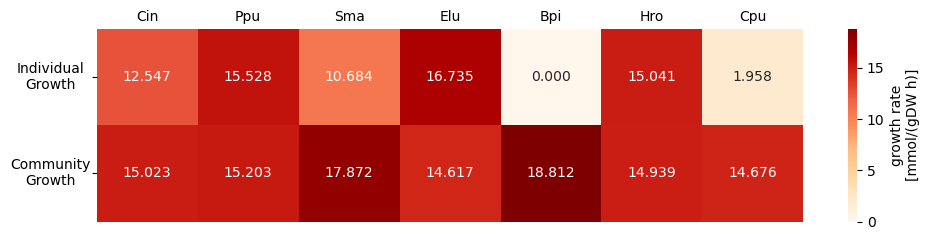

In [30]:
# Combine into 2D array for heatmap
growth_ind = [0 if x is None else x for x in growth_ind]
data = np.array([growth_ind, list(growth_com)])

#bac_names = ["AA1", "AA2", "AA3", "AA4", "AA5", "AA6", "AA7"]
bac_names = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"]
#bac_names = ["Sma\n(AA1)", "Bpi\n(AA2)", "Cpu\n(AA3)", "Elu\n(AA4)", "Cin\n(AA5)", "Hro\n(AA6)", "Ppu\n(AA7)"]

# Create a DataFrame for better labeling
df = pd.DataFrame(data,
                  index=["Individual\nGrowth", "Community\nGrowth"],
                  columns=bac_names)

tree_order = ["Cin", "Ppu", "Sma", "Elu", "Bpi", "Hro", "Cpu"]
df = df[tree_order]  # Reorder columns


# Plot
plt.figure(figsize=(10, 2.5))
ax = sns.heatmap(df, annot=True, fmt=".3f", cmap="OrRd", cbar_kws={'label': 'growth rate\n[mmol/(gDW h)]'}, vmax=data.max())


# y axis labels
ax.yaxis.set_tick_params(pad=30)  # increase space between labels and heatmap
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha="center")  # ha="right" aligns them nicely

# x axis labels
ax.xaxis.tick_top()
ax.tick_params(axis='x', length=0)  # remove x-axis ticks

plt.tight_layout()
#plt.show()
#plt.savefig("../Figures/Biomass_Ind_Com_MRM.svg")

In the following, we want to investigate why Bpi is able to grow within the community but not on its own.

In [32]:
# exchange reaction for thiamine is present in 5 out of 7 of our models
get_rxn_unknown(all_models, "EX_thm_e")

EX_thm_e is found in: ['AA2', 'AA3', 'AA4', 'AA5', 'AA7']
EX_thm_e: thm_e <=> 


In [51]:
# do pFBA with the seven-member community and gather all flux values
syncom_fluxes = get_pfba_fluxes(syncom, maize_root_medium)

In [52]:
# Bpi and Ppu are growing in the C7
print(syncom_fluxes.loc["Growth__AA2"])
print(syncom_fluxes.loc["Growth__AA7"])

18.812327776455348
15.200659706995427


In [42]:
syncom_fluxes.loc["EX_thm_e__AA2"]
# negative values are uptake

np.float64(-0.0038875246120917417)

In [45]:
syncom_fluxes.loc["EX_thm_e__AA7"]
# positive values are secretion
# Ppu is not the only donor of thiamine because there is ~0.0002 missing but Ppu is the main one

np.float64(0.0036405437645593564)

What happens when we block (a) the secretion of thiamin by Ppu and (b) block the uptake of thiamine byBpi?

In [48]:
# (a) block secretion of thiamine by Ppu
with syncom:
    syncom.reactions.get_by_id("EX_thm_e__AA7").upper_bound = 0
    syncom_fluxes_a = get_pfba_fluxes(syncom, maize_root_medium)

In [52]:
print(syncom_fluxes_a.loc["Growth__AA2"])
print(syncom_fluxes_a.loc["Growth__AA7"])
print(syncom_fluxes_a.loc["EX_thm_e__AA2"])
print(syncom_fluxes_a.loc["EX_thm_e__AA7"])

16.24277219988329
15.728801147230813
-0.0035405735525045195
-1.2131643809005623e-07


Bpi is still able to grow but less than before (~18 vs ~16). It uptakes thiamine from a different source. Ppu has a slight increase in growth (+0.5), this is likely due to the fact that it does not have to produce this vitamin fpr another strain anymore.

In [55]:
print(syncom_fluxes.loc["EX_thm_e__AA3"])
print(syncom_fluxes.loc["EX_thm_e__AA4"])
print(syncom_fluxes.loc["EX_thm_e__AA5"])
print(syncom_fluxes.loc["EX_thm_e__AA2"])

5.547638576559766e-07
1.3886458209100283e-05
1.2856364539404197e-05
-0.0038875246120917417


In [54]:
print(syncom_fluxes_a.loc["EX_thm_e__AA3"])
print(syncom_fluxes_a.loc["EX_thm_e__AA4"])
print(syncom_fluxes_a.loc["EX_thm_e__AA5"])
print(syncom_fluxes_a.loc["EX_thm_e__AA2"])

2.6653535966622812e-05
1.1076174859098176e-05
1.2152563851897114e-05
-0.0035405735525045195


In [57]:
get_met(syncom, "thm_e__AA2")

Thiamin (C12H17N4OS)
{'EX_thm_e__AA2': 'thm_e__AA2 <=> 0.14285714285714285 thm_m', 'THMtex__AA2': 'thm_e__AA2 <=> thm_p__AA2'}


In case Ppu cannot produce thiamine, Cpu increases the production. Be aware that the fluxes do not match because there is a conversion of fluxes from the medium into the bacterium model based on how MICOM designed the syncom.

In [ ]:
#(b) block uptake of thiamine for Bpi

In [203]:
with syncom:
    syncom.reactions.get_by_id("EX_thm_e__AA2").lower_bound = 0
    syncom.reactions.get_by_id("EX_thm_e__AA2").upper_bound = 0

    syncom_fluxes_b = get_pfba_fluxes(syncom, maize_root_medium)

In [204]:
print(syncom_fluxes_b.loc["Growth__AA2"])
print(syncom_fluxes_b.loc["Growth__AA7"])
print(syncom_fluxes_b.loc["EX_thm_e__AA2"])
print(syncom_fluxes_b.loc["EX_thm_e__AA7"])

15.51343328546449
15.541625857656356
0.0
0.00346320747503398


Only blocking thaimine uptake is not doing muchto the growth rate. That is why we further investigate synthesis pathways:


In [201]:
get_met(AA2, "thm_c")

Thiamin (C12H17N4OS)
{'TMN': 'h2o_c + thm_c --> 4ahmmp_c + 4mhetz_c + h_c', 'TMDPK_1': 'atp_c + thm_c --> amp_c + h_c + thmpp_c', 'THMabcpp': 'atp_c + h2o_c + thm_p --> adp_c + h_c + pi_c + thm_c'}


The Growth reaction actually needs thmpp (thiamine diphosphate). because thm can be converted into thmpp in just 1 step and for thm there is an EX reaction, this is the easiest way for the model to fulfill the thmpp needs.

However, Bpi (AA2) has pathways to synthesis thmmp (thiamine monophosphate) from other compounds:
THMPP: 4mpetz + 2mahmp --> thmmp \
PMPK: 4ampm --> 2mahmp \
HMPK1: 4ahmmp--> 4ampm

4ahmmp can be imported into the cell. Looking at fluxes, it is imported from Cpu (AA3)

In [208]:
print(syncom_fluxes_b.loc["TMPPP__AA2"])
print(syncom_fluxes_b.loc["PMPK__AA2"])
print(syncom_fluxes_b.loc["HMPK1__AA2"])
print(syncom_fluxes_b.loc["HMPPtr__AA2"]) # transport c <-> e
print(syncom_fluxes_b.loc["EX_4ahmmp_e__AA2"]) # low amount is enough because of scaling from MICOM
print(syncom_fluxes_b.loc["EX_4ahmmp_e__AA3"]) # Bpi and Cpu are the only two bacteria in the community that have this exchange reaction

0.0034609746706589775
0.003460974670658977
0.00346097467065897
0.0034609746706589666
-5.207935112294467e-09
-7.801168152737603e-10


In [207]:
with syncom:
    syncom.reactions.get_by_id("EX_thm_e__AA2").lower_bound = 0
    syncom.reactions.get_by_id("EX_thm_e__AA2").upper_bound = 0
    syncom.reactions.get_by_id("EX_4ahmmp_e__AA2").lower_bound = 0
    syncom.reactions.get_by_id("EX_4ahmmp_e__AA2").upper_bound = 0

    syncom_fluxes_b2 = get_pfba_fluxes(syncom, maize_root_medium)

In [216]:
print(syncom_fluxes_b2.loc["Growth__AA2"])
print(syncom_fluxes_b2.loc["Growth__AA7"])
print(syncom_fluxes_b2.loc["EX_thm_e__AA2"])
print(syncom_fluxes_b2.loc["EX_thm_e__AA7"])

print(syncom_fluxes_b2.loc["TMPPP__AA2"]) # reaction to synthesise thmmp is not active anymore because precursor uptake is blocked

0.3042243784268207
18.134568520144192
0.0
-0.009290129368366706
0.0


Bpi is either supplied thiamine directly or 4ahmmp (4-amino-5-hydroxymethyl-2-methylpyrimidine) to sustain growth. Both compounds do not exist in the maize root medium explaining why Bpi cannot grow on its own.

NOTE: The flux through the Growth reaction for Bpi is still 0.304. \
Thiamine has an extremely low biomass coefficient. In MICOM's community formulation (scaled by taxon abundance), this flux falls beneath the solver’s interior-point feasibility tolerance ($\epsilon_{\text{feasibility}}$), allowing the Quadratic Programming objective to assign Bpi a small non-zero growth rate without a true mass-balanced source. \
See also: https://resendislab.github.io/micom/logic.html (last section: Numerical stability and solvers)

In [223]:
with syncom:
    # Step A: Change the global community formulation strategy to 'original'
    # This forces the OptCom framework to maximize species biomass simultaneously
    syncom.strategy = "original"

    change_medium(syncom, maize_root_medium)

    syncom.reactions.get_by_id("EX_thm_e__AA2").lower_bound = 0
    syncom.reactions.get_by_id("EX_thm_e__AA2").upper_bound = 0
    syncom.reactions.get_by_id("EX_4ahmmp_e__AA2").lower_bound = 0
    syncom.reactions.get_by_id("EX_4ahmmp_e__AA2").upper_bound = 0

    # Step B: Execute via the community solver
    # We must use com.optimize() when utilizing the standard 'strategy' attributes
    sol_orig = syncom.optimize(fluxes=True)

    # Save growth rates
    df_orig = sol_orig.members[["growth_rate"]].copy()
    df_orig.rename(columns={"growth_rate": "original_growth"}, inplace=True)

print(df_orig)

              original_growth
compartments                 
AA1              1.836293e+01
AA2              6.320202e-13
AA3              1.624671e+01
AA4              1.825167e+01
AA5              2.023553e+01
AA6              2.400427e+01
AA7              1.166207e+01
medium                    NaN


The output shows that Bpi’s growth rate collapses to 6.32e-13 (which is absolute numerical zero in FBA)

sol_orig = syncom.optimize(fluxes=True) \
--> Solves the community model using the linear solver rather than the quadratic crossover method from MICOM. Linear programming solvers (using the simplex algorithm) snap directly to exact coordinate boundaries rather than floating around interior tolerances.

## Ecoplate Substrate Utilisation

In [31]:
metab_axis = ["Phenylethylamine", "Putrescine", "Glycyl-glutamic acid", "L-arginine", "Asparagine", "Phenylalanine", "Serine", "Threonine", "Glycerol-phosphate", "Cellobiose", "Mannitol", "Xylose", "Glucose-1-phosphate", "Acetyl-glucosamine", "4-Hydroxy benzoic acid", "Galacturonic acid", "Malic acid", "2-Hydroxy-benzoic acid", "Lactose", "Butyric acid", "Water (Control)"]
# These are the metabolites from the Ecoplate however only the ones that have an equivalent metabolite in the models.

[11/07/26 16:44:47] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=13912417;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=13912418;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

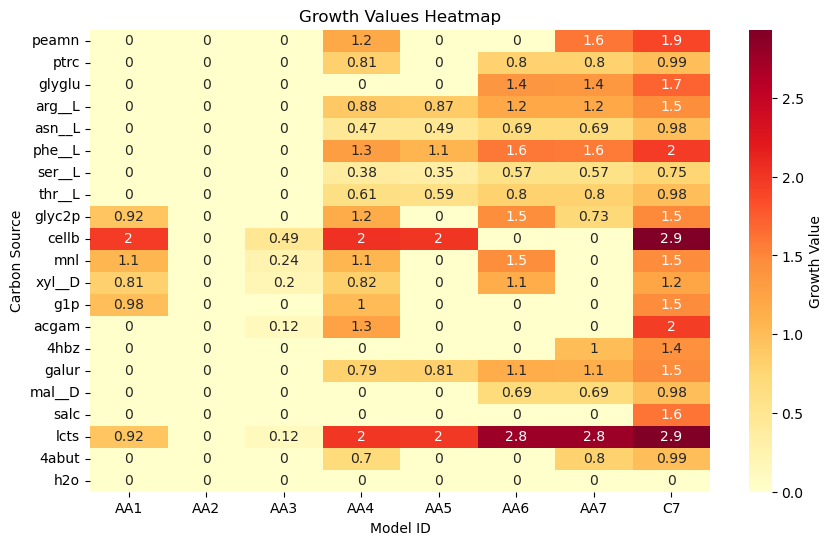

In [32]:
ecoplate_df = create_medium(ecoplate_rxns, m9_rxn, all_models, 10, carbon_only=True)
# it should create on "warning" that a carbon source is missing, this is for the test with water, so we actually have no carbon and we want to make sure that there is no growth to ensure correct functioning of the models

In [36]:
# for nicer visualisation: better labels
ecoplate_df.index = metab_axis
ecoplate_df.index.name = "Substrate"
ecoplate_df.columns = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu", "C7"]
ecoplate_df = ecoplate_df.fillna(0)

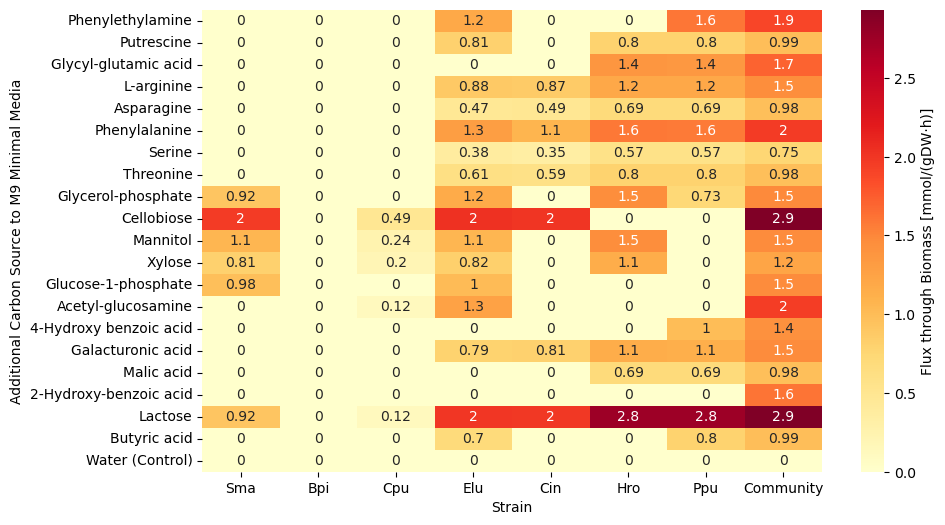

In [34]:
# Create a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(ecoplate_df, annot=True, cmap="YlOrRd", cbar_kws={'label': 'Flux through Biomass [mmol/(gDW·h)]'})
# plt.title("")
plt.xlabel("Strain")
#plt.yticks(ticks=np.arange(len(metab_axis)), labels=metab_axis)
plt.ylabel("Additional Carbon Source to M9 Minimal Media")
#plt.savefig("../Figures/ecoplate.svg", format="svg", bbox_inches="tight")
plt.show()

In [37]:
# Export as csv
#ecoplate_df.to_csv("../Datasets/in_silico_data/Ecoplate_S.csv")

## Minimal media growth assay (For Cross-Feeding)

9 different carbon sources were used for the minimal medium growth assay in vitro (M9 + single carbon source):
- Glucose (glc__D)
- Sucrose (sucr)
- Xylose (xyl__D)
- Malate (mal__L or maybe mal__D)
- Pyruvate (pyr)
- Succinate (succ)
- Alanine (ala__L or maybe ala__D)
- Glutamate (glu__L or glu__D)
- Glycine (gly)

In [38]:
carbon_sources = ["EX_glc__D_e", "EX_sucr_e", "EX_xyl__D_e", ["EX_mal__L_e", "EX_mal__L_e"], "EX_pyr_e", "EX_succ_e", ["EX_ala__L_e", "EX_ala__L_e"], "EX_glu__L_e", "EX_gly_e"]

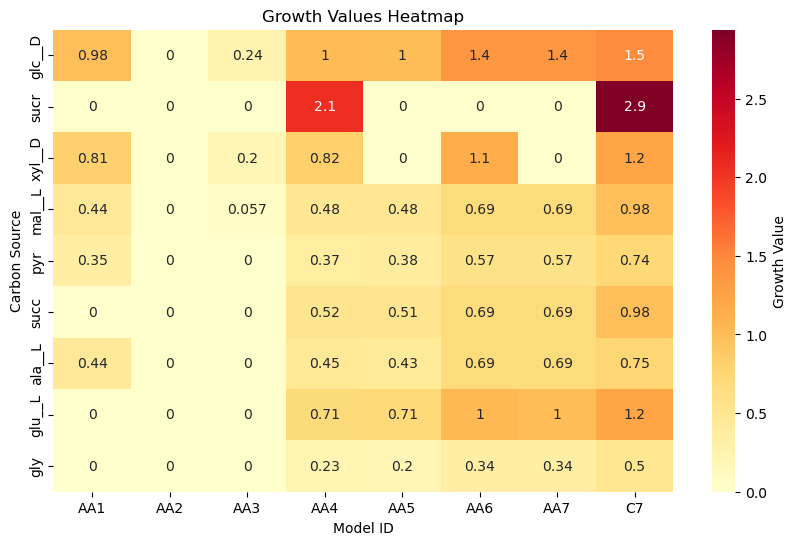

In [39]:
carbon_df = create_medium(carbon_sources, m9_rxn, all_models, 10, carbon_only=True)

In [40]:
# nicer plot with nicer labels
carbon_df.index = ["Glucose", "Sucrose", "Xylose", "Malate", "Pyruvate", "Succinate", "Alanine", "Glutamate", "Glycine"]
carbon_df.index.name = "Substrate"
carbon_df.columns = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu", "C7"]
carbon_df = carbon_df.fillna(0)

In [41]:
carbon_df_numeric = carbon_df.apply(pd.to_numeric, errors='coerce') # Ensure numeric
annot_str = carbon_df_numeric.applymap(custom_format)

/tmp/ipykernel_4096/2202862689.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_str = carbon_df_numeric.applymap(custom_format)


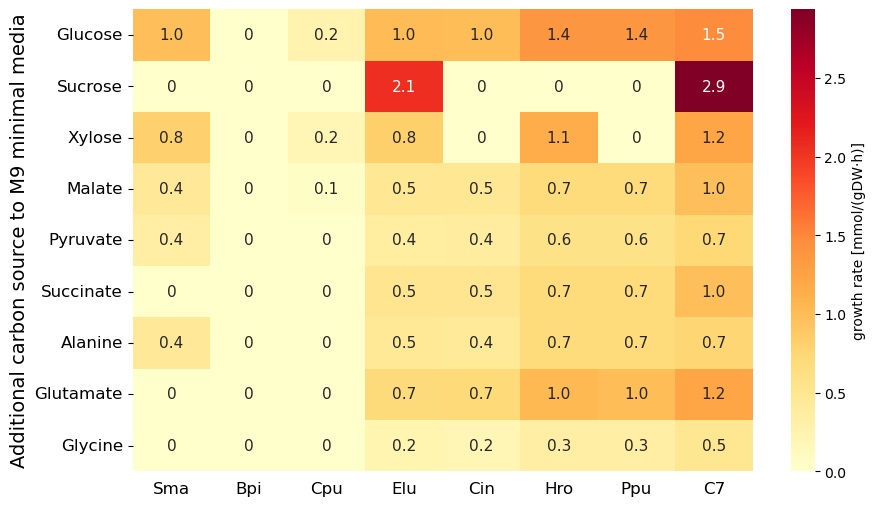

In [42]:
# Create a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(carbon_df, annot=annot_str, fmt="", cmap="YlOrRd", cbar_kws={'label': 'growth rate [mmol/(gDW·h)]'}, annot_kws={"size": 11})
# plt.title("")
# plt.xlabel("Strain")
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)

plt.gca().tick_params(axis='x', which='both', bottom=False, top=False)


plt.ylabel("Additional carbon source to M9 minimal media", fontsize=14)
#plt.savefig("../../Cross_Feeding_Step1_2.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [43]:
# Export as csv
#carbon_df.to_csv("../Datasets/in_silico_data/Growth_Carbon_Sources_S.csv")

## Uptakes and Secretions

### per individual model

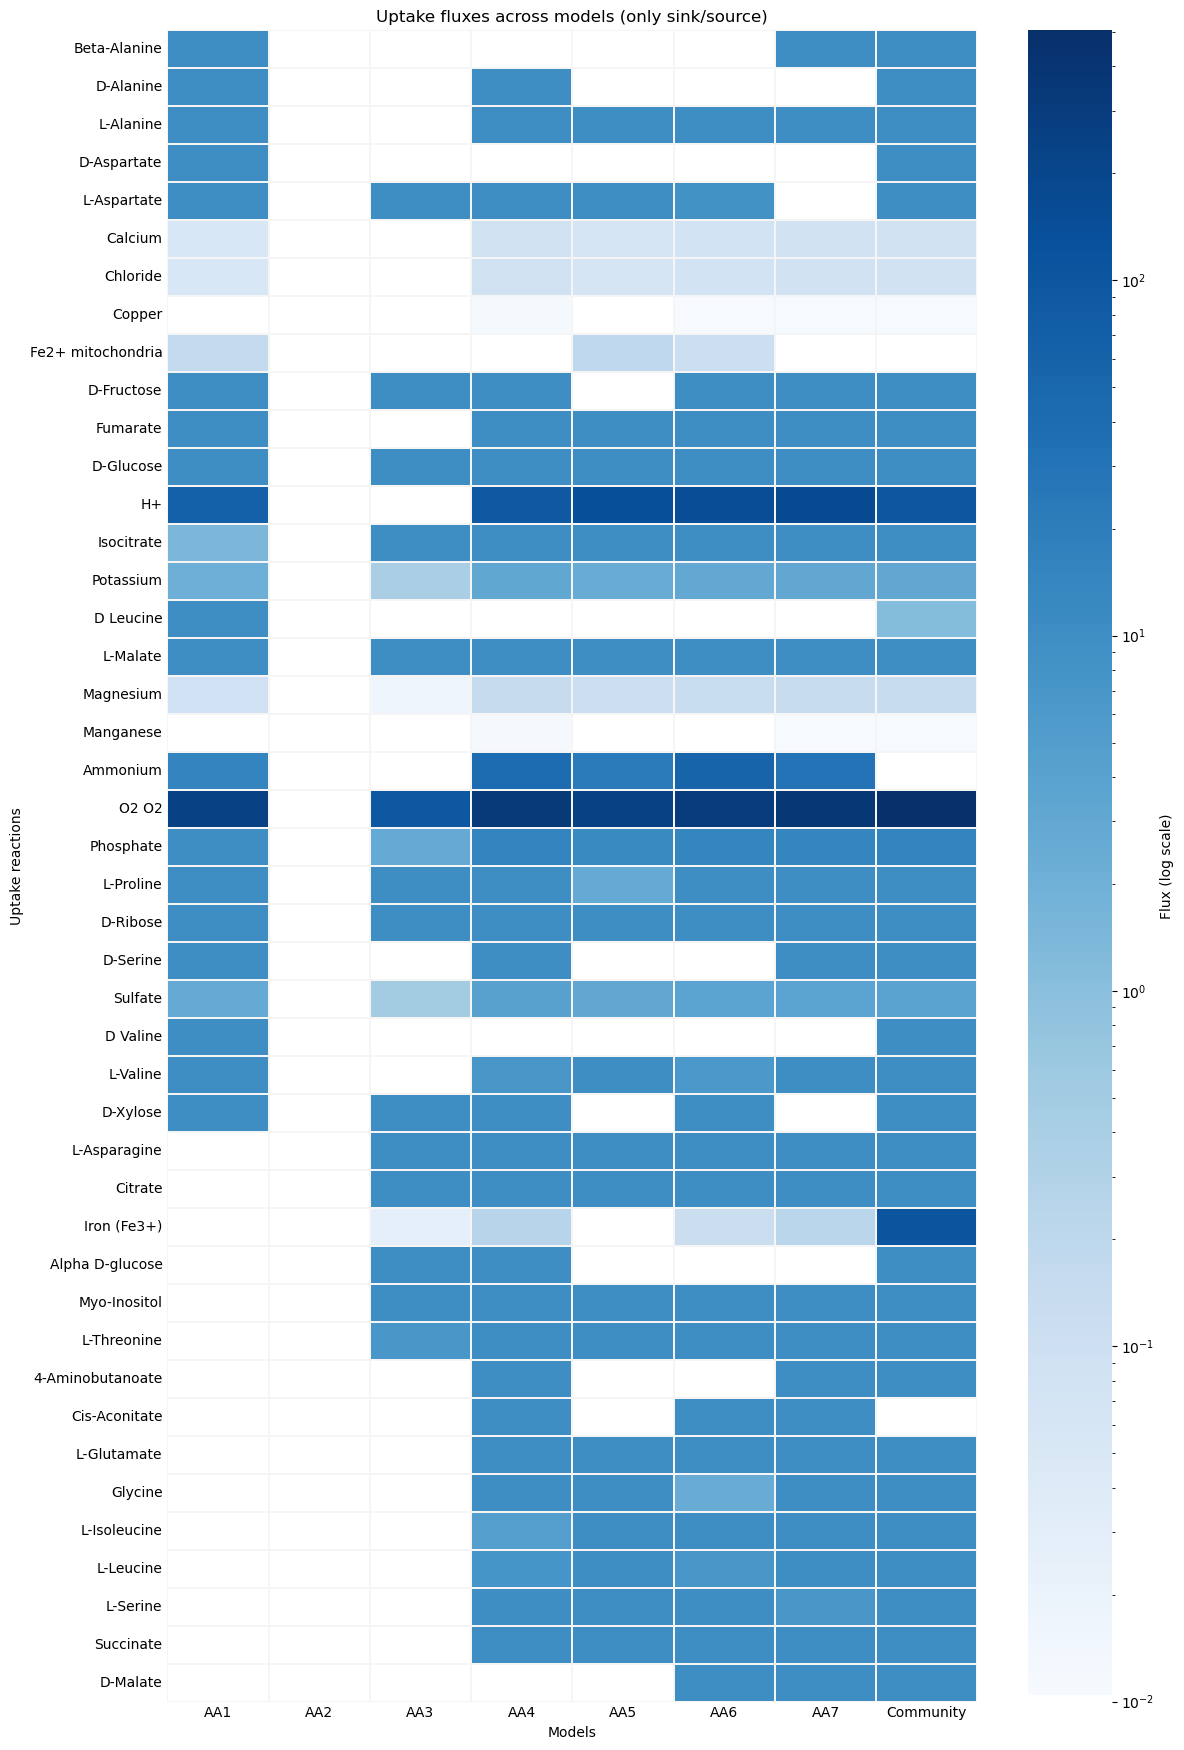

In [44]:
# the code for the community works in a way it only looks at EX reactions into/from the medium and outside and NO EX into/from a model into the medium
uptake_df = uptake_secret_heatmap(all_models, "uptake", maize_root_medium, c7_all_ex = "no", vmin=0.01)

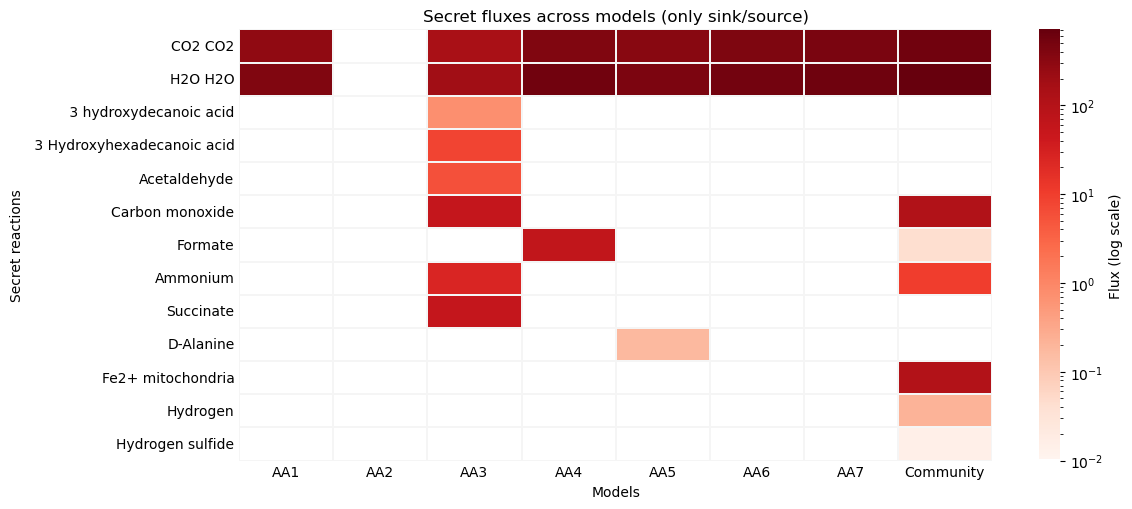

In [30]:
secret_df = uptake_secret_heatmap(all_models, "secret", maize_root_medium, c7_all_ex = "no", vmin=0.01)
# sometimes the community does not produces hydrogen sulfide as it is a very low amount (~0.014) and pFBA is not deterministic

In [49]:
secret_df.columns = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu", "C7"]

In [50]:
# Export as csv
secret_df.to_csv("../Datasets/in_silico_data/Secretion_S.csv", na_rep=0)

In [60]:
uptake_names_mapping = {
    "Aconitate": ["Cis-Aconitate"],
    "Alanine": ["Beta-Alanine", "D-Alanine", "L-Alanine"],
    "Asparagine": ["L-Asparagine"],
    "Aspartate": ["D-Aspartate", "L-Aspartate"],
    "Iron": ["Fe2+ mitochondria", "Iron (Fe3+)"],
    "Isoleucine": ["L-Isoleucine"],
    "Fructose": ["D-Fructose"],
    "GABA": ["4-Aminobutanoate"],
    "Glucose": ["D-Glucose", "Alpha D-glucose"],
    "Glutamate": ["L-Glutamate"],
    "Proton": ["H+"],
    "Leucine": ["D Leucine", "L-Leucine"],
    "Malate": ["L-Malate", "D-Malate"],
    "Myo-inositol": ["Myo-Inositol"],
    "Oxygen": ["O2 O2"],
    "Proline": ["L-Proline"],
    "Ribose": ["D-Ribose"],
    "Serine": ["D-Serine", "L-Serine"],
    "Threonine": ["L-Threonine"],
    "Valine": ["D Valine", "L-Valine"],
    "Xylose": ["D-Xylose"],
}

In [62]:
# create reverse mapping: value -> key
reverse_mapping = {
    value: key
    for key, values in uptake_names_mapping.items()
    for value in values
}

uptake_df = uptake_df.rename(
    index=lambda idx: reverse_mapping.get(idx, idx)
)

# sort by index
uptake_df = uptake_df.sort_index()

# group rows with the same index and sum them or do mean
uptake_df = uptake_df.groupby(uptake_df.index).mean()
#uptake_df = uptake_df.groupby(uptake_df.index).sum()

# treat NaNs as 0
uptake_df = uptake_df.fillna(0)

uptake_df.index.name = "Metabolite"
uptake_df.columns = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu", "C7"]

# Export cleaned up uptake_df as csv
# uptake_df.to_csv("../Datasets/in_silico_data/Depletion_primary_S.csv")

### uptakes within community

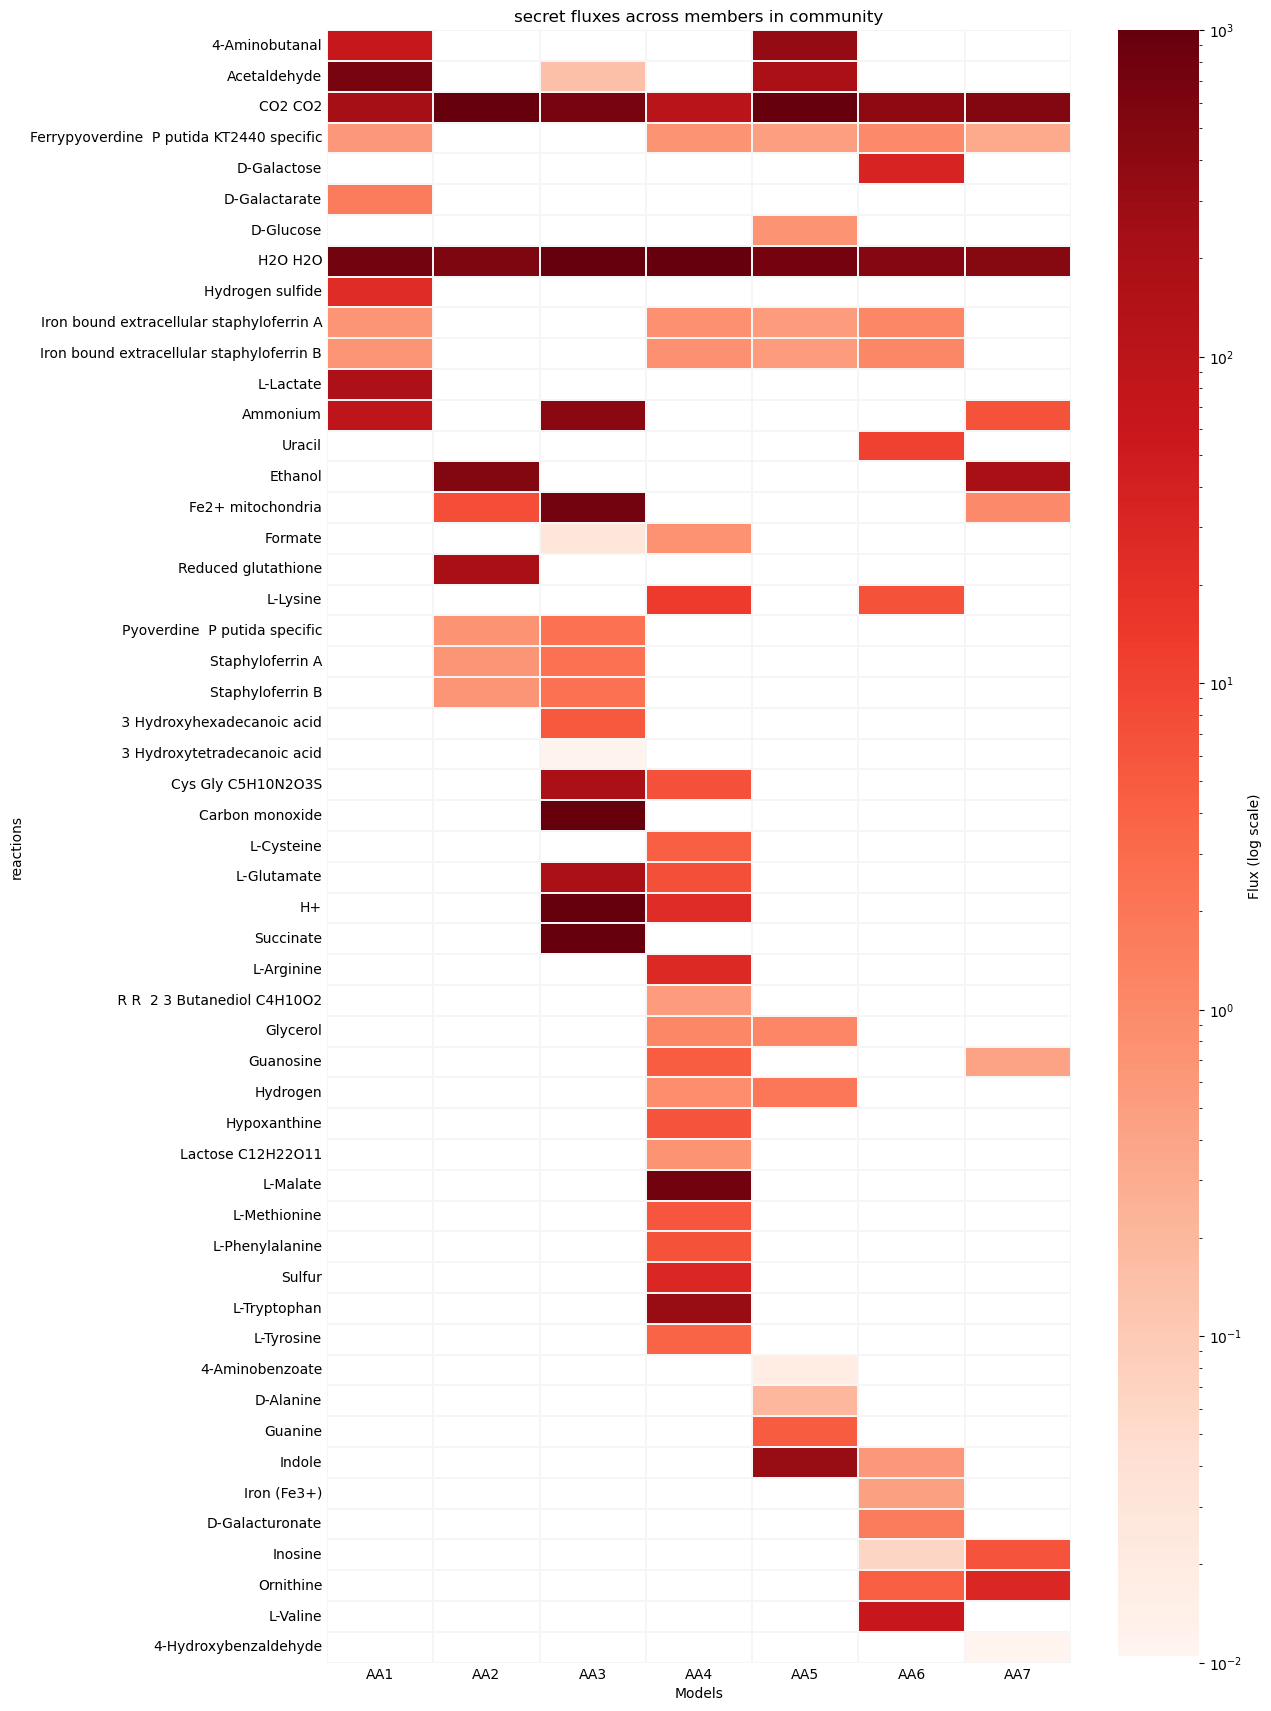

In [50]:
df_secret_com = heatmap_fluxes_withinCommunity(syncom, models, maize_root_medium, "secret", vmin=0.01)

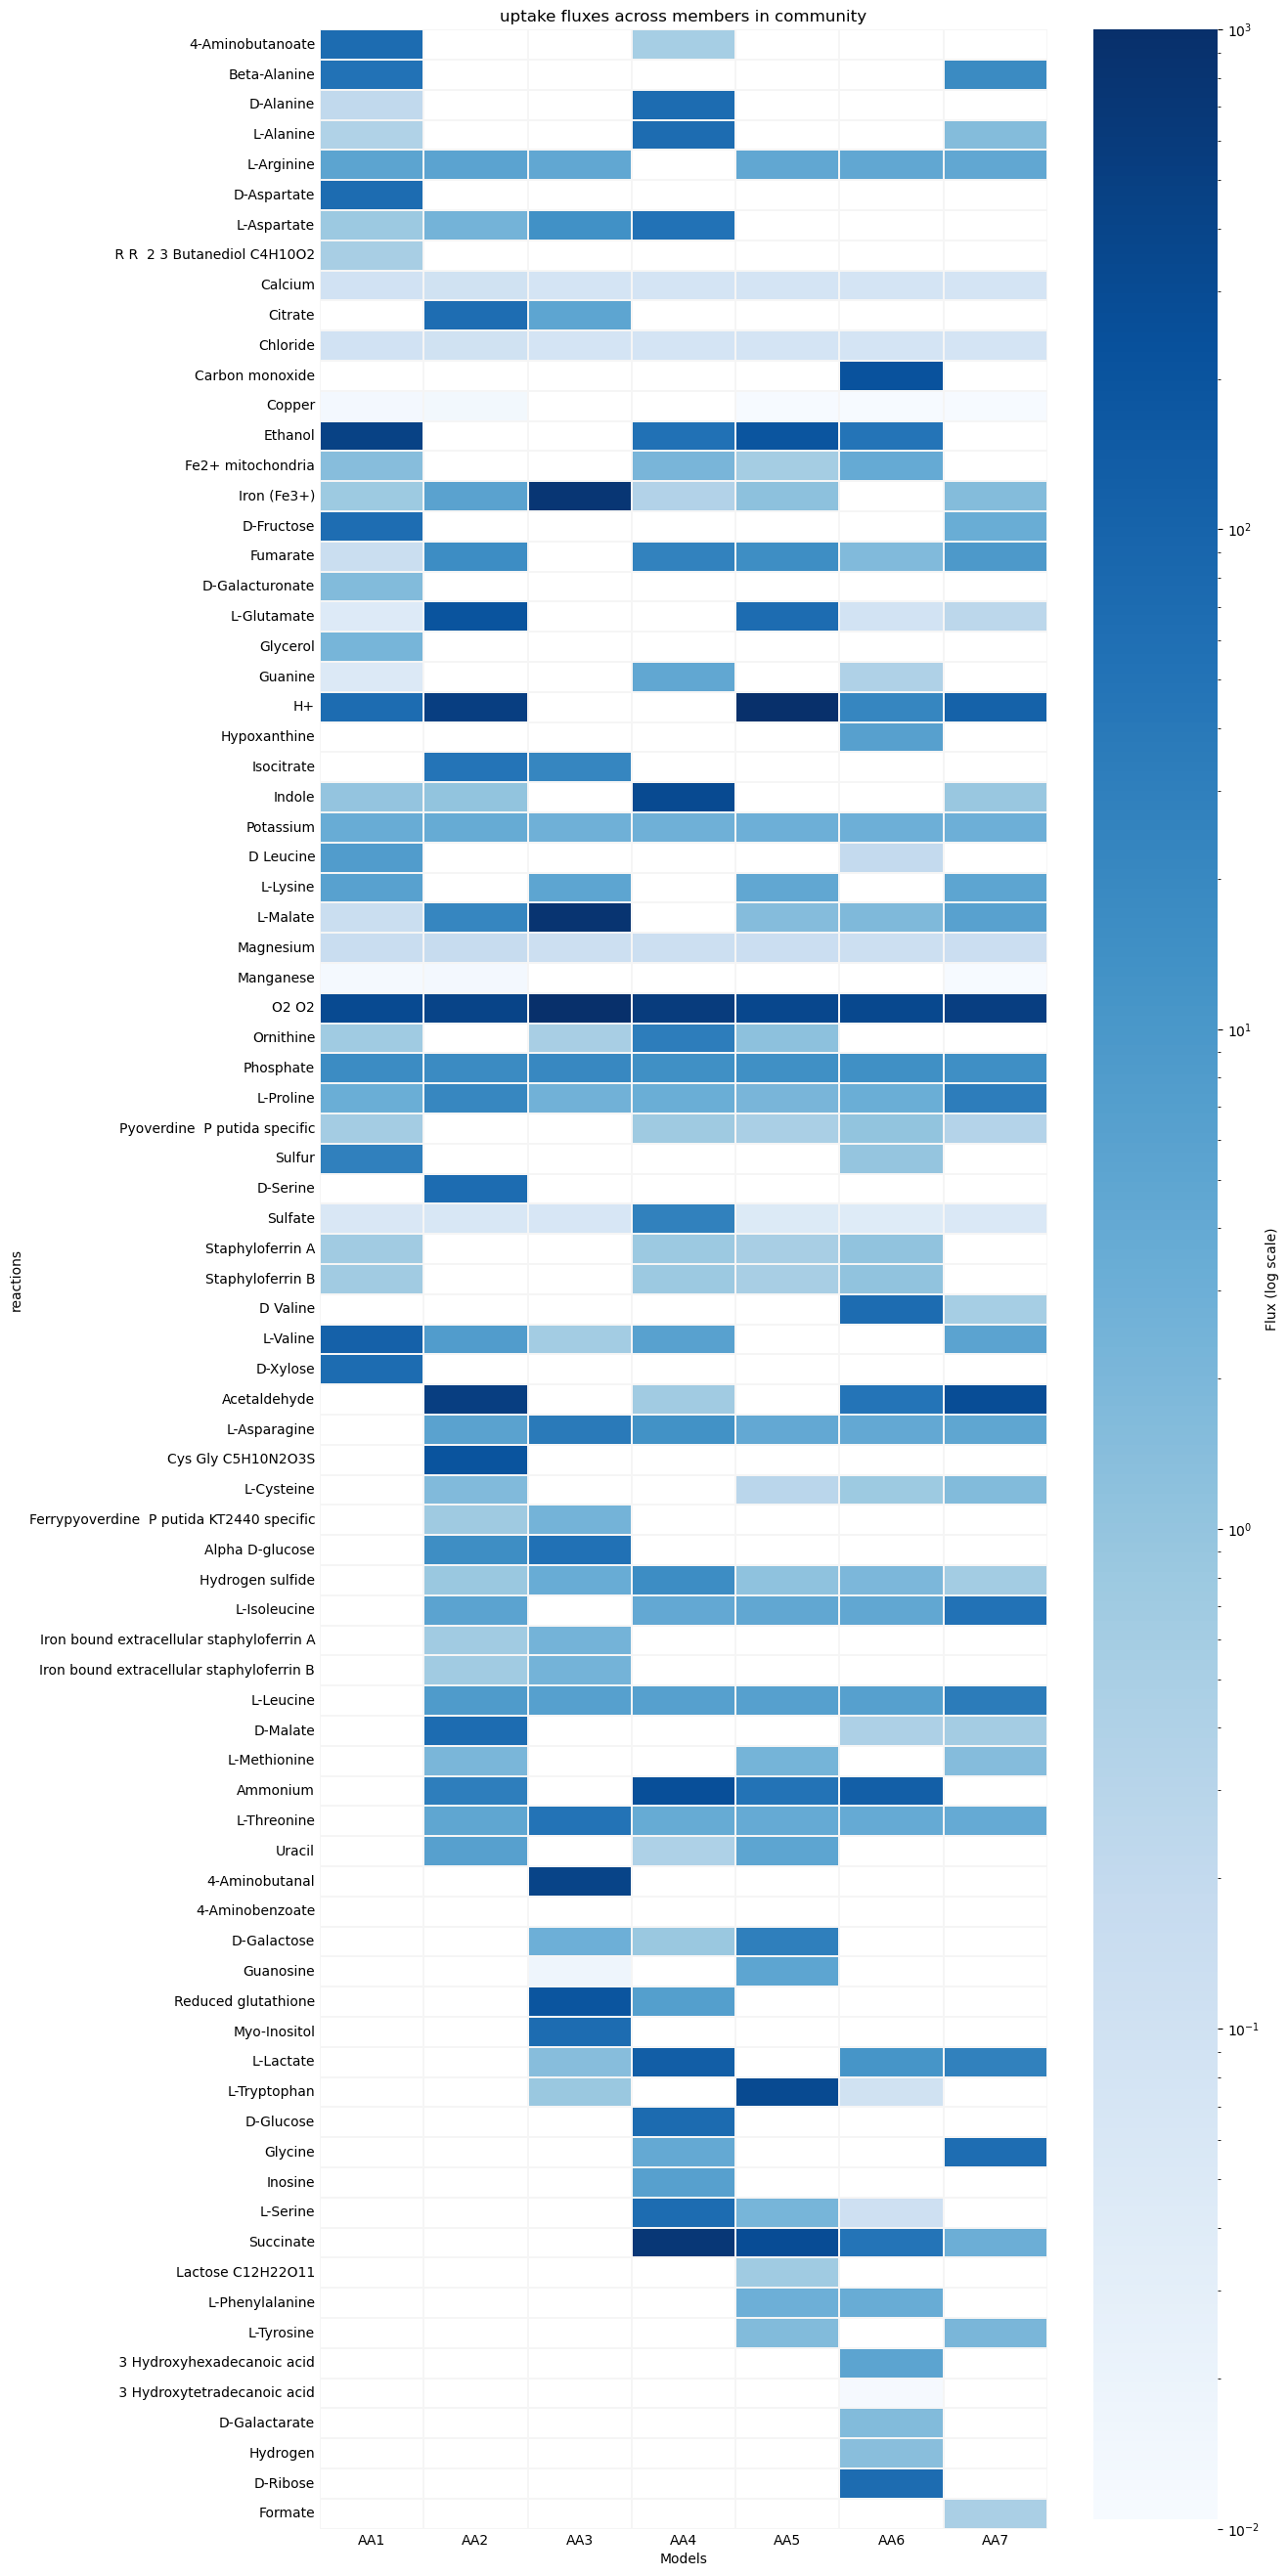

In [48]:
df_uptakes_com = heatmap_fluxes_withinCommunity(syncom, models, maize_root_medium, "uptake", vmin=0.01)

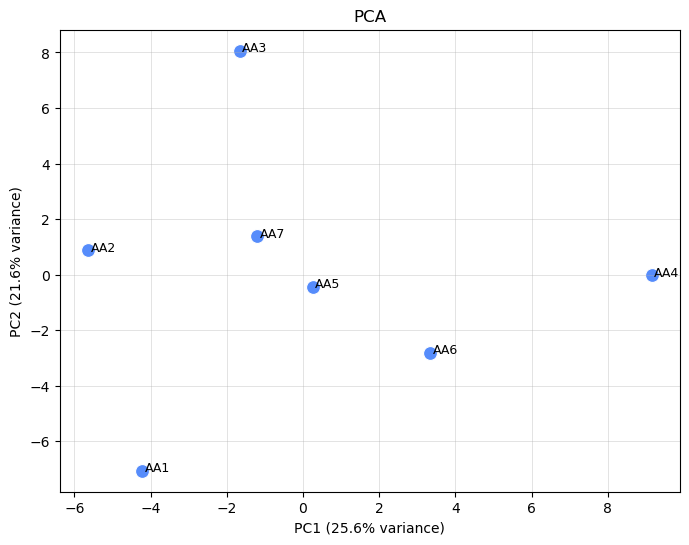

In [49]:
pca(df_uptakes_com.T)

# Simulations II - Cross-Feeding

## According to in vitro analyses

In [63]:
#donors = ["Fresh", "AA4", "AA5", "AA6", "AA7"]
donors = ["Fresh", "AA4", "AA6", "AA7"]
possible_carbons = [["EX_glc__D_e"], ["EX_mal__L_e"], ["EX_ala__L_e"]]

In [64]:
mrm_rxns = [rxn for rxn in mrm_only_carbon["reaction"]]
possible_carbons_mrm = possible_carbons + [mrm_rxns]

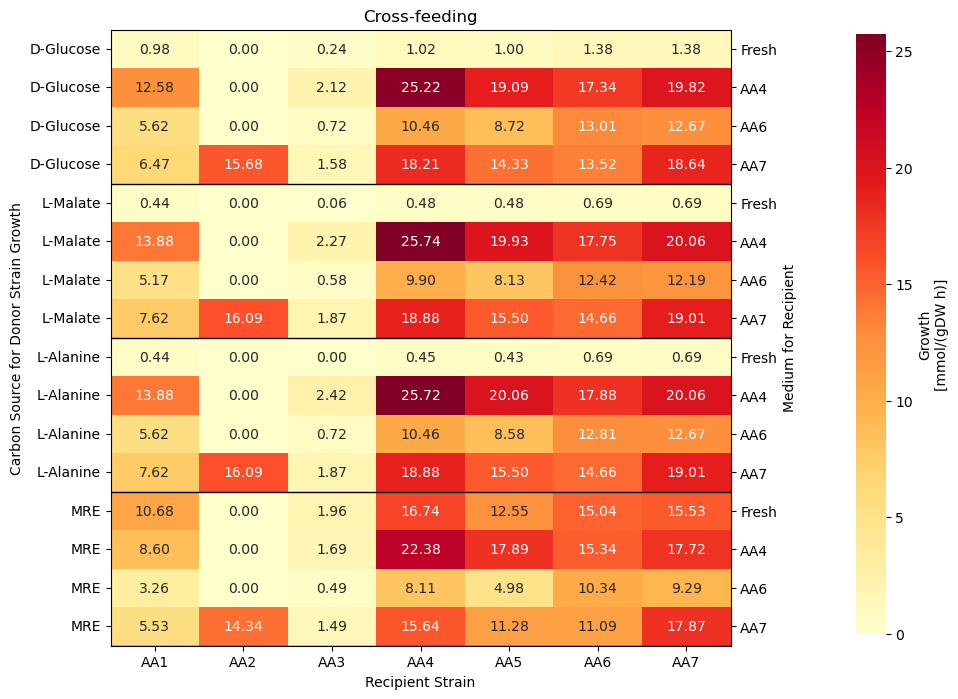

In [53]:
whole_cross_feeding(models, donors, possible_carbons_mrm, m9, 10, fva=True)
# parameter explanation: setting fixed_bounds=10 makes that it checks which compounds are secreted but the amount for uptake is set to 10 instead of the secreted amount. That is why we have quite high growth rates here. Actual secretion is much smaller.

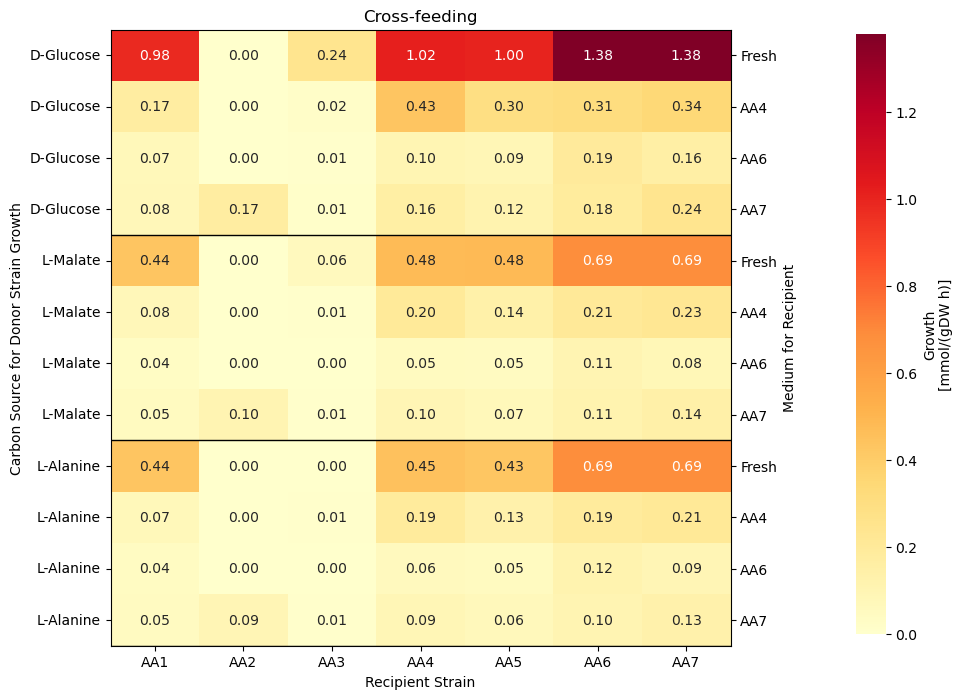

In [65]:
cross_feed_df = whole_cross_feeding(models, donors, possible_carbons, m9, fva=True, return_df=True)

/tmp/ipykernel_4096/1518647455.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_str = cross_feed_numeric.applymap(custom_format)


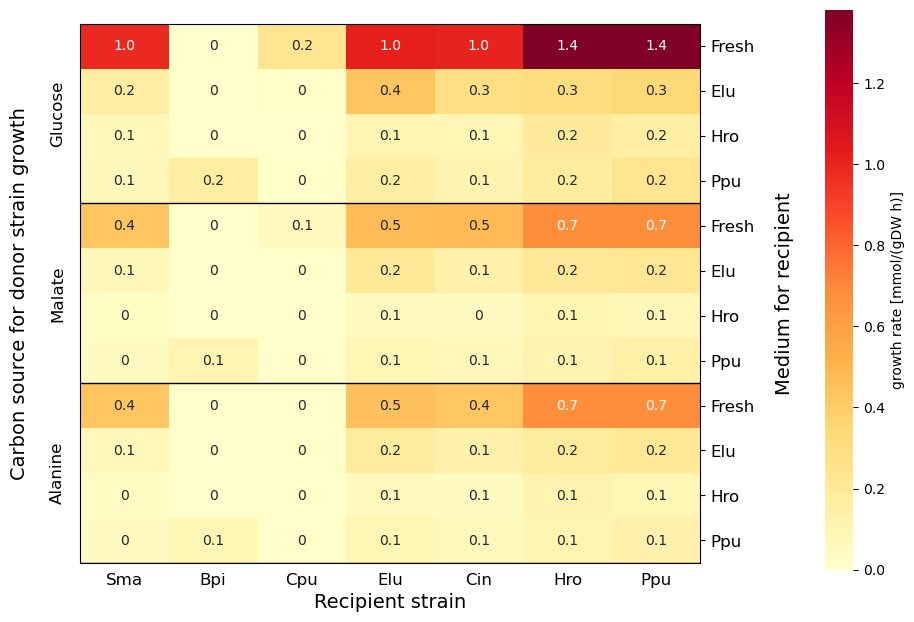

In [66]:
plt.figure(figsize=(10, 7))

cross_feed_numeric = cross_feed_df.apply(pd.to_numeric, errors='coerce')
annot_str = cross_feed_numeric.applymap(custom_format)


ax = sns.heatmap(
    cross_feed_df, annot=annot_str, cmap="YlOrRd", fmt="", linewidths=0.0, linecolor='none',
    cbar_kws={"label": "growth rate [mmol/(gDW h)]", "orientation":"vertical"}
)

# Access and move colorbar
cbar = ax.collections[0].colorbar
cbar.ax.set_position([0.87, 0.1, 0.03, 0.8])  # [x, y, width, height]

ax.set_ylabel("Carbon source for donor strain growth", labelpad=30, fontsize=14)
group_names = ["Glucose", "Malate", "Alanine"]
group_size = len(donors)  # how many rows per group

# Remove the left y tick labels (to avoid repetition)
ax.set_yticklabels([])

# Add group labels manually
for i, group in enumerate(group_names):
    # y position: middle of each block
    y_pos = (i * group_size) + group_size / 2
    ax.text(
        -0.17, y_pos, group, va="center", ha="right", rotation=90,
        fontsize=12, transform=ax.transData
    )

# Right y-axis labels
ax_right = ax.twinx()
ax_right.set_ylim(ax.get_ylim())
ax_right.set_ylabel("Medium for recipient", fontsize=14, labelpad=15)

#right_labels = ["Fresh", "Elu", "Cin", "Hro", "Ppu"] * 3
right_labels = ["Fresh", "Elu", "Hro", "Ppu"] * 3
ax_right.set_yticks(np.arange(len(right_labels)) + 0.5)
ax_right.set_yticklabels(right_labels, rotation=0, fontsize=12)


for i in range(len(donors), len(donors)*len(possible_carbons)+1, len(donors)):  # add horizontal lines
    plt.hlines(i, *plt.xlim(), color='black', linewidth=1)

custom_x_labels = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"]
ax.set_xticklabels(custom_x_labels, fontsize=12)
ax.set_xlabel("Recipient strain", fontsize=14)

# Remove automatic ticks/grid
ax.tick_params(axis='y', which='both', left=False)
ax.tick_params(axis='x', which='both', bottom=False)
ax.set_facecolor("none")
ax.grid(False)

#plt.title("Cross-feeding")
#plt.savefig("../Figures/MA_Results/Cross_Feeding_Step2.svg", format="svg", bbox_inches="tight")
plt.show()

In [68]:
cross_feed_df.columns = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"]

metabolites = ["Glucose", "Malate", "Alanine"]
#conditions = ["Fresh", "Elu", "Cin", "Hro", "Ppu"]
conditions = ["Fresh", "Elu", "Hro", "Ppu"]

pairs = [f"{m}_{c}" for m, c in product(metabolites, conditions)]

cross_feed_df.index = pairs
cross_feed_df.index.name = "Medium"

# Export as csv
#cross_feed_df.to_csv("../Datasets/in_silico_data/Cross-Feeding_S.csv")

## In silico anaylses of cross-feeding within the community

The above results are for each model on their own, i.e. can one bacterium grow on the exudate of another. However, we also want to check what metabolites the bacteria provide each other in the community. \
That means we need to: (I) get all EX reactions that are secretions and (II) all uptake reactions where the metabolites are not in the medium and are part of the secretions. \
For cross-feeding we need to match them, i.e. a secretion of a metabolite must be the uptake from another model.

In [61]:
syncom_fluxes = get_pfba_fluxes(syncom, maize_root_medium)

### qualitative

In [62]:
# get all secretions
threshold_sec = 0.001
secretions = syncom_fluxes[(syncom_fluxes.index.str.startswith("EX_"))
                           & (syncom_fluxes > threshold_sec)
                           & (~syncom_fluxes.index.str.endswith("_m"))]

In [63]:
# get uptakes
#threshold_up = 0.001
uptakes = syncom_fluxes[(syncom_fluxes.index.str.startswith("EX_"))
                        & (syncom_fluxes < -threshold_sec)
                        & (~syncom_fluxes.index.str.endswith("_m"))]

In [64]:
# Build DataFrames with columns: metabolite, strain, flux
sec_df = pd.DataFrame([
    (*split_rxn_id(rxn), flux) for rxn, flux in secretions.items()
], columns=["metabolite", "strain", "flux"])

upt_df = pd.DataFrame([
    (*split_rxn_id(rxn), flux) for rxn, flux in uptakes.items()
], columns=["metabolite", "strain", "flux"])

# Merge on metabolite name, but require different strains
cross_feed = sec_df.merge(upt_df, on="metabolite", suffixes=("_sec", "_upt"))
cross_feed = cross_feed[cross_feed["strain_sec"] != cross_feed["strain_upt"]]

print(cross_feed)


      metabolite strain_sec    flux_sec strain_upt    flux_upt
0    EX_4abutn_e        AA1   69.433716        AA3 -412.249287
1    EX_4abutn_e        AA5  342.815370        AA3 -412.249287
2      EX_4hbz_e        AA1    0.002227        AA6   -0.001491
3      EX_4hbz_e        AA1    0.002227        AA7   -0.004304
4      EX_4hbz_e        AA5    0.003391        AA6   -0.001491
..           ...        ...         ...        ...         ...
255    EX_hdca_e        AA7    0.001274        AA4   -0.001493
256   EX_ocdca_e        AA7    0.001269        AA4   -0.001493
257  EX_ocdcea_e        AA7    0.001251        AA4   -0.001476
258   EX_pheme_e        AA7    0.003587        AA2   -0.004008
259     EX_thm_e        AA7    0.003753        AA2   -0.003955

[260 rows x 5 columns]


In [65]:
# unique amounts of uptakes that were previously secreted
tuples_list = list(zip(cross_feed['metabolite'], cross_feed['strain_upt']))
unique_list = list(set(tuples_list))
model_counts = Counter(model for metabolite, model in unique_list)
model_counts

Counter({'AA6': 28,
         'AA5': 25,
         'AA4': 25,
         'AA1': 22,
         'AA7': 20,
         'AA3': 20,
         'AA2': 19})

In [66]:
# unique amounts of secretions that are also uptaken
tuples_list = list(zip(cross_feed['metabolite'], cross_feed['strain_sec']))
unique_list = list(set(tuples_list))
model_counts = Counter(model for metabolite, model in unique_list)
model_counts

Counter({'AA4': 23,
         'AA3': 19,
         'AA5': 14,
         'AA7': 13,
         'AA6': 13,
         'AA1': 10,
         'AA2': 7})

In [67]:
cross_feed_condensed = cross_feed.groupby("metabolite").agg({
    "strain_sec": lambda x: list(sorted(x.unique())),
    "strain_upt": lambda x: list(sorted(x.unique()))
}).reset_index()
# ATTENTION: this was not matched by fluxes! I.e. AA1 donates 10,5 of met and AA2 uptakes like 5,3

In [68]:
# Sample data preparation
edges = []
for _, row in cross_feed_condensed.iterrows():
    donors = row['strain_sec']
    recipients = row['strain_upt']
    edges.extend(list(product(donors, recipients)))

edges_df = pd.DataFrame(edges, columns=['source', 'target'])
edges_agg = edges_df.groupby(['source', 'target']).size().reset_index(name='weight')


In [90]:
custom_colors = {
    "AA1": "#e5c494",   # pastel wine
    "AA2": "#a6d854",   # soft coral
    "AA3": "#8da0cb",   # soft blue
    "AA4": "#e78ac3",   # pastel green
    "AA5": "#fc8d62",   # muted teal
    "AA6": "#ffd92f",   # soft turquoise
    "AA7": "#66c2a5"    # soft gold
}

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
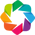

In [91]:
# Initialize HoloViews with Bokeh
hv.extension('bokeh')

# Define nodes and links
nodes = pd.DataFrame({'name': sorted(set(edges_agg['source']).union(edges_agg['target']))})
links = edges_agg

# Map node colours
nodes['color'] = nodes['name'].map(custom_colors)
# Map edge colours based on source strain
links['color'] = links['source'].map(custom_colors)

# Create HoloViews Dataset
nodes_ds = hv.Dataset(nodes, 'name')
chord = hv.Chord((links, nodes_ds), ['source', 'target'], ['weight', 'color'])

# Define options for the chord diagram
chord.opts(
    opts.Chord(
        node_color='color',          # Node colour
        edge_color=dim('color'),
        labels='name',               # Display node labels
        width=600,                   # Width of the plot
        height=600,                  # Height of the plot
        node_size=20,                # Size of the nodes
        edge_alpha=0.85,             # Transparency of the edges
        edge_line_width=1.5,         # Line width of the edges
        label_text_color='black'     # Color of the node labels
    )
)

# EXPORT & SAVE as HTML
hv.save(chord, 'cross_feeding_chord.html')
# viewing holoview plots in jupyter notebook is difficult, so exporting it is easier


### quantitative - with _m

In [96]:
# --- FILTER FLUXES ---
threshold_sec = 0.001

# Secretions
secretions_withM = syncom_fluxes[
    ((syncom_fluxes.index.str.startswith("EX_")) & (syncom_fluxes > threshold_sec) & (~syncom_fluxes.index.str.endswith("_m"))) |
    ((syncom_fluxes.index.str.startswith("EX_")) & (syncom_fluxes.index.str.endswith("_m")) & (syncom_fluxes < -threshold_sec))
]

# Uptakes
uptakes_withM = syncom_fluxes[
    ((syncom_fluxes.index.str.startswith("EX_")) & (syncom_fluxes < -threshold_sec) & (~syncom_fluxes.index.str.endswith("_m"))) |
    ((syncom_fluxes.index.str.startswith("EX_")) & (syncom_fluxes.index.str.endswith("_m")) & (syncom_fluxes > threshold_sec))
]

# --- SPLIT REACTION IDS ---
def split_rxn_id(rxn_id):
    match = re.match(r"^(.*)__AA(\d+)$", rxn_id)
    if match:
        return match.group(1), f"AA{match.group(2)}"
    if rxn_id.endswith("_m"):
        return rxn_id[:-2] + "_e", "m"
    return rxn_id, None

# --- BUILD DATAFRAMES ---
sec_df_witM = pd.DataFrame(
    [(*split_rxn_id(rxn), flux) for rxn, flux in secretions_withM.items()],
    columns=["metabolite", "strain_sec", "flux_sec"]
)

upt_df_witM = pd.DataFrame(
    [(*split_rxn_id(rxn), flux) for rxn, flux in uptakes_withM.items()],
    columns=["metabolite", "strain_upt", "flux_upt"]
)

# Ensure numeric and positive
sec_df_witM["flux_sec"] = pd.to_numeric(sec_df_witM["flux_sec"], errors="coerce").abs()
upt_df_witM["flux_upt"] = pd.to_numeric(upt_df_witM["flux_upt"], errors="coerce").abs()

# Drop NaNs
sec_df_witM = sec_df_witM.dropna(subset=["metabolite", "strain_sec", "flux_sec"])
upt_df_witM = upt_df_witM.dropna(subset=["metabolite", "strain_upt", "flux_upt"])

# --- AGGREGATE FOR SANKEY ---
# Donor -> Medium (one secretion per metabolite per donor)
sec_unique = sec_df_witM.groupby(["strain_sec", "metabolite"], as_index=False).agg({"flux_sec": "first"})

# Medium -> Recipient (sum of uptakes per recipient+metabolite)
upt_agg = upt_df_witM.groupby(["strain_upt", "metabolite"], as_index=False).agg({"flux_upt": "sum"})



# --- BUILD NODES ---
strains = sorted(set(sec_df_witM["strain_sec"]).union(set(upt_df_witM["strain_upt"])))
nodes = [f"{s}_sec" for s in strains] + ["Medium"] + [f"{s}_upt" for s in strains]
node_indices = {node: i for i, node in enumerate(nodes)}

# Colors: same for left/right copies of each strain
palette = px.colors.qualitative.Set3
strain_colors = {s: palette[i % len(palette)] for i, s in enumerate(strains)}
node_colors = [strain_colors[s] for s in strains] + ["lightgrey"] + [strain_colors[s] for s in strains]

# --- BUILD LINKS ---
sec_links = [
    {"source": node_indices[f"{row.strain_sec}_sec"], "target": node_indices["Medium"],
     "value": float(row.flux_sec), "label": row.metabolite}
    for _, row in sec_unique.iterrows()
]

upt_links = [
    {"source": node_indices["Medium"], "target": node_indices[f"{row.strain_upt}_upt"],
     "value": float(row.flux_upt), "label": row.metabolite}
    for _, row in upt_agg.iterrows()
]

links = sec_links + upt_links

# --- RECONSTRUCT CROSS_FEED DF ---
# this is for me sanity, so I have all data as an overview and can compare with the plot
cross_feed_df = sec_unique.merge(upt_agg, on="metabolite", how="outer")
cross_feed_df = cross_feed_df[cross_feed_df["strain_sec"] != cross_feed_df["strain_upt"]]
cross_feed_df["flux_sec"] = pd.to_numeric(cross_feed_df["flux_sec"], errors="coerce").fillna(0)
cross_feed_df["flux_upt"] = pd.to_numeric(cross_feed_df["flux_upt"], errors="coerce").fillna(0)
#####


# --- SANKEY PLOT ---
# Update Sankey plot
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=40,
        thickness=18,
        line=dict(color="black", width=0.5),
        label=nodes,
        color=node_colors
    ),
    link=dict(
        source=[l["source"] for l in links],
        target=[l["target"] for l in links],
        value=[l["value"] for l in links],
        label=[l["label"] for l in links],
        color="lightgrey"
    )
)])

fig.update_layout(title_text="Cross-feeding Sankey (donor once, uptakes summed, metabolite colored)",
                  font_size=12, width=1200, height=900)
fig.show()

### quantitative - without _m

In [97]:
# --- FILTER FLUXES ---
threshold_sec = 0.001

# Secretions
secretions_withoutM = syncom_fluxes[
    ((syncom_fluxes.index.str.startswith("EX_")) & (syncom_fluxes > threshold_sec) & (~syncom_fluxes.index.str.endswith("_m")))
]

# Uptakes
uptakes_withoutM = syncom_fluxes[
    ((syncom_fluxes.index.str.startswith("EX_")) & (syncom_fluxes < -threshold_sec) & (~syncom_fluxes.index.str.endswith("_m")))
]

# --- SPLIT REACTION IDS ---
def split_rxn_id(rxn_id):
    """Split into metabolite part and strain ID."""
    met, strain = rxn_id.rsplit("__", 1) # splitting starts from the right
    return met, strain


# --- BUILD DATAFRAMES ---
sec_df_witoutM = pd.DataFrame(
    [(*split_rxn_id(rxn), flux) for rxn, flux in secretions_withoutM.items()],
    columns=["metabolite", "strain_sec", "flux_sec"]
)

upt_df_witoutM = pd.DataFrame(
    [(*split_rxn_id(rxn), flux) for rxn, flux in uptakes_withoutM.items()],
    columns=["metabolite", "strain_upt", "flux_upt"]
)

# Ensure numeric and positive
sec_df_witoutM["flux_sec"] = pd.to_numeric(sec_df_witoutM["flux_sec"], errors="coerce").abs()
upt_df_witoutM["flux_upt"] = pd.to_numeric(upt_df_witoutM["flux_upt"], errors="coerce").abs()

# Drop NaNs
sec_df_witoutM = sec_df_witoutM.dropna(subset=["metabolite", "strain_sec", "flux_sec"])
upt_df_witoutM = upt_df_witoutM.dropna(subset=["metabolite", "strain_upt", "flux_upt"])

# --- AGGREGATE FOR SANKEY ---
# Donor -> Medium (one secretion per metabolite per donor)
sec_unique = sec_df_witoutM.groupby(["strain_sec", "metabolite"], as_index=False).agg({"flux_sec": "first"})

# Medium -> Recipient (sum of uptakes per recipient+metabolite)
upt_agg = upt_df_witoutM.groupby(["strain_upt", "metabolite"], as_index=False).agg({"flux_upt": "sum"})

# --- BUILD NODES ---
strains = sorted(set(sec_df_witoutM["strain_sec"]).union(set(upt_df_witoutM["strain_upt"])))
nodes = [f"{s}_sec" for s in strains] + ["Medium"] + [f"{s}_upt" for s in strains]
node_indices = {node: i for i, node in enumerate(nodes)}

# Colors: same for left/right copies of each strain
palette = px.colors.qualitative.Set3
strain_colors = {s: palette[i % len(palette)] for i, s in enumerate(strains)}
node_colors = [strain_colors[s] for s in strains] + ["lightgrey"] + [strain_colors[s] for s in strains]

# --- BUILD LINKS ---
sec_links = [
    {"source": node_indices[f"{row.strain_sec}_sec"], "target": node_indices["Medium"],
     "value": float(row.flux_sec), "label": row.metabolite}
    for _, row in sec_unique.iterrows()
]

upt_links = [
    {"source": node_indices["Medium"], "target": node_indices[f"{row.strain_upt}_upt"],
     "value": float(row.flux_upt), "label": row.metabolite}
    for _, row in upt_agg.iterrows()
]

links = sec_links + upt_links

# --- RECONSTRUCT CROSS_FEED DF ---
# this is for me sanity, so I have all data as an overview and can compare with the plot
cross_feed_df = sec_unique.merge(upt_agg, on="metabolite", how="outer")
cross_feed_df = cross_feed_df[cross_feed_df["strain_sec"] != cross_feed_df["strain_upt"]]
cross_feed_df["flux_sec"] = pd.to_numeric(cross_feed_df["flux_sec"], errors="coerce").fillna(0)
cross_feed_df["flux_upt"] = pd.to_numeric(cross_feed_df["flux_upt"], errors="coerce").fillna(0)
#####


# --- SANKEY PLOT ---
# Update Sankey plot
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=40,
        thickness=18,
        line=dict(color="black", width=0.5),
        label=nodes,
        color=node_colors
    ),
    link=dict(
        source=[l["source"] for l in links],
        target=[l["target"] for l in links],
        value=[l["value"] for l in links],
        label=[l["label"] for l in links],
        color="lightgrey"
    )
)])

fig.update_layout(title_text="Cross-feeding Sankey (without medium)",
                  font_size=12, width=1200, height=900)
fig.show()

### quantitative - without _m but with scaling

In [98]:
# --- FILTER FLUXES ---
threshold_sec = 0.001

# Secretions
secretions_withoutM = syncom_fluxes[
    ((syncom_fluxes.index.str.startswith("EX_")) & (syncom_fluxes > threshold_sec) & (~syncom_fluxes.index.str.endswith("_m")))
]

# Uptakes
uptakes_withoutM = syncom_fluxes[
    ((syncom_fluxes.index.str.startswith("EX_")) & (syncom_fluxes < -threshold_sec) & (~syncom_fluxes.index.str.endswith("_m")))
]

# --- SPLIT REACTION IDS ---
def split_rxn_id(rxn_id):
    """Split into metabolite part and strain ID."""
    met, strain = rxn_id.rsplit("__", 1) # splitting starts from the right
    return met, strain


# --- BUILD DATAFRAMES ---
sec_df_witoutM = pd.DataFrame(
    [(*split_rxn_id(rxn), flux) for rxn, flux in secretions_withoutM.items()],
    columns=["metabolite", "strain_sec", "flux_sec"]
)

upt_df_witoutM = pd.DataFrame(
    [(*split_rxn_id(rxn), flux) for rxn, flux in uptakes_withoutM.items()],
    columns=["metabolite", "strain_upt", "flux_upt"]
)

# Ensure numeric and positive
sec_df_witoutM["flux_sec"] = pd.to_numeric(sec_df_witoutM["flux_sec"], errors="coerce").abs()
upt_df_witoutM["flux_upt"] = pd.to_numeric(upt_df_witoutM["flux_upt"], errors="coerce").abs()

# Drop NaNs
sec_df_witoutM = sec_df_witoutM.dropna(subset=["metabolite", "strain_sec", "flux_sec"])
upt_df_witoutM = upt_df_witoutM.dropna(subset=["metabolite", "strain_upt", "flux_upt"])

# --- AGGREGATE FOR SANKEY ---
sec_unique = sec_df_witoutM
upt_agg = upt_df_witoutM

# --- BUILD NODES ---
strains = sorted(set(sec_df_witoutM["strain_sec"]).union(set(upt_df_witoutM["strain_upt"])))
nodes = [f"{s}_sec" for s in strains] + ["Medium"] + [f"{s}_upt" for s in strains]
node_indices = {node: i for i, node in enumerate(nodes)}

# Colors: same for left/right copies of each strain
palette = px.colors.qualitative.Set3
strain_colors = {s: palette[i % len(palette)] for i, s in enumerate(strains)}
node_colors = [strain_colors[s] for s in strains] + ["lightgrey"] + [strain_colors[s] for s in strains]


####
def scale_flux(row, mode, n_strains=7,):
    if mode == "S":
        # Secretion from AAx into medium
        return row['flux_sec'] / n_strains
    elif mode == "U":
        #
        return row['flux_upt'] / n_strains
    else:
        return "Error"

sec_unique['flux_sec_scaled'] = sec_unique.apply(scale_flux, axis=1, args=("S",))
upt_agg['flux_upt_scaled'] = upt_agg.apply(scale_flux, axis=1, args=("U",))
####


# --- BUILD LINKS ---
sec_links = [
    {"source": node_indices[f"{row.strain_sec}_sec"], "target": node_indices["Medium"],
     "value": float(row.flux_sec_scaled), "label": row.metabolite}
    for _, row in sec_unique.iterrows()
]

upt_links = [
    {"source": node_indices["Medium"], "target": node_indices[f"{row.strain_upt}_upt"],
     "value": float(row.flux_upt_scaled), "label": row.metabolite}
    for _, row in upt_agg.iterrows()
]

links = sec_links + upt_links

# --- RECONSTRUCT CROSS_FEED DF ---
# this is for me sanity, so I have all data as an overview and can compare with the plot
cross_feed_df = sec_unique.merge(upt_agg, on="metabolite", how="outer")
cross_feed_df = cross_feed_df[cross_feed_df["strain_sec"] != cross_feed_df["strain_upt"]]
cross_feed_df["flux_sec"] = pd.to_numeric(cross_feed_df["flux_sec"], errors="coerce").fillna(0)
cross_feed_df["flux_upt"] = pd.to_numeric(cross_feed_df["flux_upt"], errors="coerce").fillna(0)
#####


# --- SANKEY PLOT ---
# Update Sankey plot
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=40,
        thickness=18,
        line=dict(color="black", width=0.5),
        label=nodes,
        color=node_colors
    ),
    link=dict(
        source=[l["source"] for l in links],
        target=[l["target"] for l in links],
        value=[l["value"] for l in links],
        label=[l["label"] for l in links],
        color="lightgrey"
    )
)])

fig.update_layout(title_text="Cross-feeding Sankey (without medium)",
                  font_size=12, width=1200, height=900)
fig.show()

### quantitative - with _m and with scaling

In [99]:
# --- FILTER FLUXES ---
def upt_sec_for_syncom(syncom_pfba_fluxes):
    threshold_sec = 0.001
    # Secretions
    secretions_withM = syncom_pfba_fluxes[
        ((syncom_pfba_fluxes.index.str.startswith("EX_")) & (syncom_pfba_fluxes > threshold_sec)
         & (~syncom_pfba_fluxes.index.str.endswith("_m"))) |
        ((syncom_pfba_fluxes.index.str.startswith("EX_")) & (syncom_pfba_fluxes.index.str.endswith("_m"))
         & (syncom_pfba_fluxes < -threshold_sec))
    ]

    # Uptakes
    uptakes_withM = syncom_pfba_fluxes[
        ((syncom_pfba_fluxes.index.str.startswith("EX_")) & (syncom_pfba_fluxes < -threshold_sec)
         & (~syncom_pfba_fluxes.index.str.endswith("_m"))) |
        ((syncom_pfba_fluxes.index.str.startswith("EX_")) & (syncom_pfba_fluxes.index.str.endswith("_m"))
         & (syncom_pfba_fluxes > threshold_sec))
    ]
    return secretions_withM, uptakes_withM

###### WHICH FLUXES TO USE
secretions_withM, uptakes_withM = upt_sec_for_syncom(syncom_fluxes)
######

# --- SPLIT REACTION IDS ---
def split_rxn_id(rxn_id):
    match = re.match(r"^(.*)__AA(\d+)$", rxn_id)
    if match:
        return match.group(1), f"AA{match.group(2)}"
    if rxn_id.endswith("_m"):
        return rxn_id[:-2] + "_e", "m"
    return rxn_id, None


# --- BUILD DATAFRAMES ---
sec_df_withM = pd.DataFrame(
    [(*split_rxn_id(rxn), flux) for rxn, flux in secretions_withM.items()],
    columns=["metabolite", "strain_sec", "flux_sec"]
)

upt_df_withM = pd.DataFrame(
    [(*split_rxn_id(rxn), flux) for rxn, flux in uptakes_withM.items()],
    columns=["metabolite", "strain_upt", "flux_upt"]
)

# Ensure numeric and positive
sec_df_withM["flux_sec"] = pd.to_numeric(sec_df_withM["flux_sec"], errors="coerce").abs()
upt_df_withM["flux_upt"] = pd.to_numeric(upt_df_withM["flux_upt"], errors="coerce").abs()

# Drop NaNs
sec_df_withM = sec_df_withM.dropna(subset=["metabolite", "strain_sec", "flux_sec"])
upt_df_withM = upt_df_withM.dropna(subset=["metabolite", "strain_upt", "flux_upt"])

# --- AGGREGATE FOR SANKEY ---
sec_unique = sec_df_withM
upt_agg = upt_df_withM

# --- BUILD NODES ---
strains = sorted(set(sec_df_withM["strain_sec"]).union(set(upt_df_withM["strain_upt"])))
nodes = [f"{s}_sec" for s in strains] + [""] + [f"{s}_upt" for s in strains]

# Replace "m" nodes with m_source / m_sink
nodes = [
    *(f"{s}_sec" if s != "m" else "m_source" for s in strains),
    "",  # middle node will be annotated as "shared compartment (_m)"
    *(f"{s}_upt" if s != "m" else "m_sink" for s in strains)
]

node_indices = {node: i for i, node in enumerate(nodes)}

# Colors: same for left/right copies of each strain
palette = px.colors.qualitative.Set2
strain_colors = {s: palette[i % len(palette)] for i, s in enumerate(strains)}
node_colors = [strain_colors[s] for s in strains] + ["lightgrey"] + [strain_colors[s] for s in strains]


####
def scale_flux(row, mode, n_strains=7,):
    if mode == "S":
        if row["strain_sec"] != "m":
            return row['flux_sec'] / n_strains
        else:
            return row['flux_sec']
    elif mode == "U":
        if row["strain_upt"] != "m":
            return row['flux_upt'] / n_strains
        else:
            return row['flux_upt']
    else:
        return "Error"

sec_unique['flux_sec_scaled'] = sec_unique.apply(scale_flux, axis=1, args=("S",))
upt_agg['flux_upt_scaled'] = upt_agg.apply(scale_flux, axis=1, args=("U",))
####


# --- BUILD LINKS ---
sec_links = [
    {"source": node_indices["m_source"] if row.strain_sec=="m" else node_indices[f"{row.strain_sec}_sec"],
     "target": node_indices[""],
     "value": float(row.flux_sec_scaled),
     "label": row.metabolite}
    for _, row in sec_unique.iterrows()
]

upt_links = [
    {"source": node_indices[""],
     "target": node_indices["m_sink"] if row.strain_upt=="m" else node_indices[f"{row.strain_upt}_upt"],
     "value": float(row.flux_upt_scaled),
     "label": row.metabolite}
    for _, row in upt_agg.iterrows()
]


links = sec_links + upt_links

# --- RECONSTRUCT CROSS_FEED DF ---
# this is for me sanity, so I have all data as an overview and can compare with the plot
cross_feed_df = sec_unique.merge(upt_agg, on="metabolite", how="outer")
cross_feed_df = cross_feed_df[cross_feed_df["strain_sec"] != cross_feed_df["strain_upt"]]
cross_feed_df["flux_sec"] = pd.to_numeric(cross_feed_df["flux_sec"], errors="coerce").fillna(0)
cross_feed_df["flux_upt"] = pd.to_numeric(cross_feed_df["flux_upt"], errors="coerce").fillna(0)
#####


# --- SANKEY PLOT ---

# Build the Sankey figure
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=40,
        thickness=18,
        line=dict(color="black", width=0.5),
        label=nodes,
        color=node_colors
    ),
    link=dict(
        source=[l["source"] for l in links],
        target=[l["target"] for l in links],
        value=[l["value"] for l in links],
        label=[l["label"] for l in links],
        color="lightgray",
        hovercolor="darkgray"
    )
)])


# --- ANNOTATIONS IN THE PLOT

# Add rotated annotation for the middle node
fig.add_annotation(
    x=0.5,  # roughly center of the plot
    y=0.5,  # adjust vertically as needed
    text="shared compartment ( _m)",
    showarrow=False,
    textangle=-90,   # rotates text 90 degrees
    font=dict(size=12, color="black")
)

# show
fig.update_layout(title_text="Cross-feeding Sankey (with medium)",
                  font_size=12, width=1200, height=1000)
fig.show()

# Simulations III - Vitamins

In [69]:
Bvitamins = {
    "B1": ["thm", "thmmp", "thmpp"],
    "B2": ["ribflv"],
    "B3": ["ncam", "nicnt", "nac"],
    "B5": ["pnto__R"],
    "B6": ["pydam", "pydxn", "pydx"],
    "B7": ["btn"],
    "B9": ["fol", "5mthf"],
    "B12": ["b12", "adocbl", "C06453", "adocbi"]
}

In [70]:
for model in models.values():
    check_B_vitamins(model)

AA1 - Missing B vitamins in: B12
AA2 - All B vitamins are present.
AA3 - All B vitamins are present.
AA4 - All B vitamins are present.
AA5 - Missing B vitamins in: B12
AA6 - All B vitamins are present.
AA7 - Missing B vitamins in: B7


B1 - Thiamine (C12H17N4OS+) \
BIGG: thm (thiamine), thmmp (Thiamin monophosphate), thmpp (Thiamin diphosphate, active version in body)

B2 - Riboflavin (C17H20N4O6) \
BIGG: ribflv

B3 - Niacin (nicotinic acid)/Niacinamide/Nicotinamide riboside \
--> can be converted into NAD \
BIGG: ncam (Nicotinaminde), nac (Nicotinate), rnam (Ribosylnicotinamide)

B5 - Pantothenic acid (C9H17NO5) \
BIGG: pnto__R (R-pantothenate)

B6 - Pyridoxine/Pyridoxal/Pyridoxamine \
BIGG: pydxn/pydx/pydam

B7 - Biotin (C10H16N2O3S) \
BIGG: btn (biotin)

B9 - Folate (C19H19N7O6) \
BIGG: fol (folate), 5mthf (5-Methyltetrahydrofolate, active form)

B12 - Cobalamin (C63H88CoN14O14P) \
BIGG: b12 (vitamin b12), C06453 (methylcobalamin), adocbl (adenosylcobalamin), adocbi (Adenosyl cobinamide)

In [80]:
EX_V8 = ["EX_thm_e", "EX_ribflv_e", "EX_nac_e", "EX_rnam_e", "EX_pnto__R_e", "EX_pydxn_e", "EX_btn_e", "EX_fol_e"]
EX_V8_names = ["Thiamin", "Riboflavin", "Niacin", "Ribosylnicotinamide", "Pantothenate", "Pyridoxine", "Biotin", "Folate"]
# nac and rnam both B3

## V8 - Full Vitamin Mix

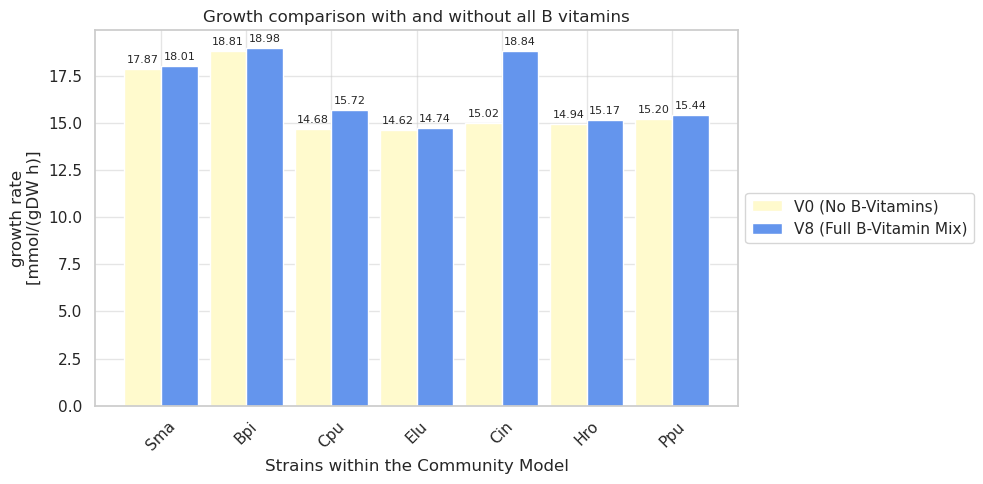

In [104]:
# add vitamins to the maize root medium for the SynCom
vitamin_growth_plots(syncom, maize_root_medium, EX_V8)

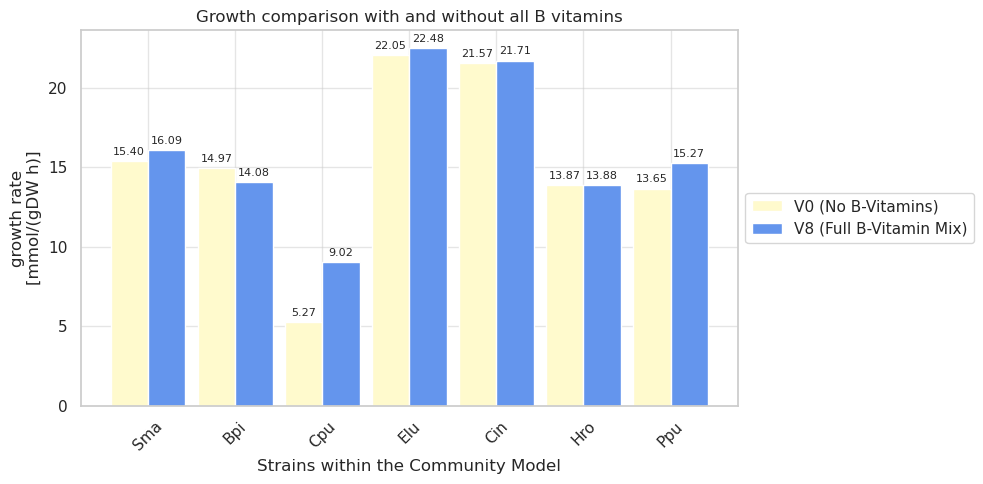

In [105]:
# add vitamins to a simple medium for the SynCom
vitamin_growth_plots(syncom, medium_for_vitaminTesting, EX_V8)

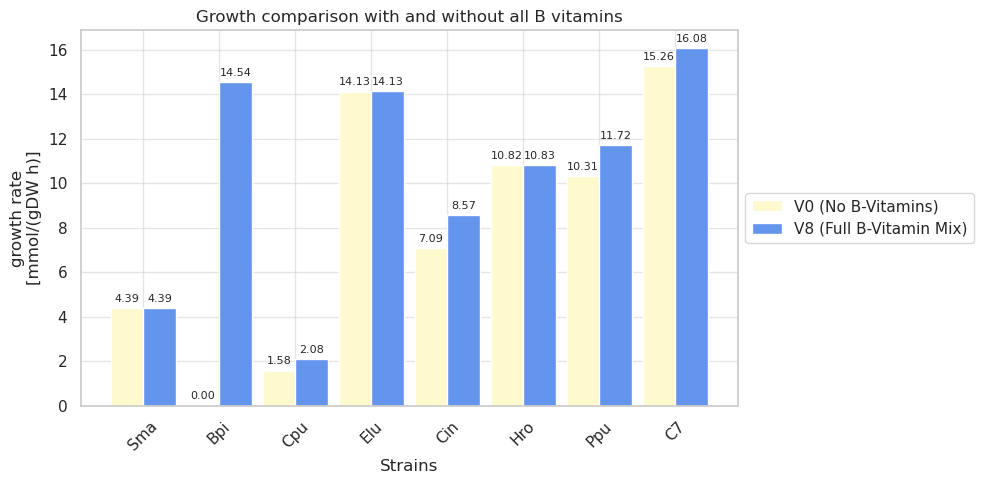

In [106]:
# add vitamins to a simple medium for all individual models and the SynCom (Growth is averaged across all ind. models for SynCom)
vitamin_growth_plots(all_models, medium_for_vitaminTesting, EX_V8)

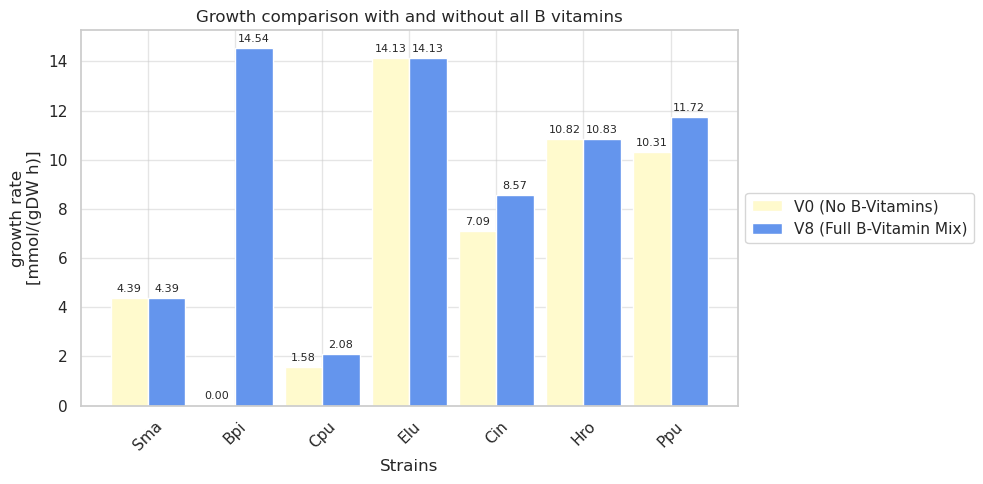

In [108]:
# add vitamins to a simple medium for all individual models
# these re-creates the in vitro experiments (without C7 in comparison to the plot above)
vitamin_growth_plots(models, medium_for_vitaminTesting, EX_V8)

In [72]:
# Instead of creating a plot, we are saving the data in a df for exporting it as csv
vitamin_res = vitamin_growth_plots(models, medium_for_vitaminTesting, EX_V8, return_df=True)
#vitamin_res.to_csv("../Datasets/in_silico_data/Vitamins_S.csv", index=False)

## V1 & V7 - adding one or removing one vitamin

In [73]:
# this was also done in vitro with an even smaller medium, i.e. one carbon source and the M9
ala = ["EX_ala__L_e","EX_ala__D_e","EX_ala_B_e"]
glu = ["EX_glc__D_e"]

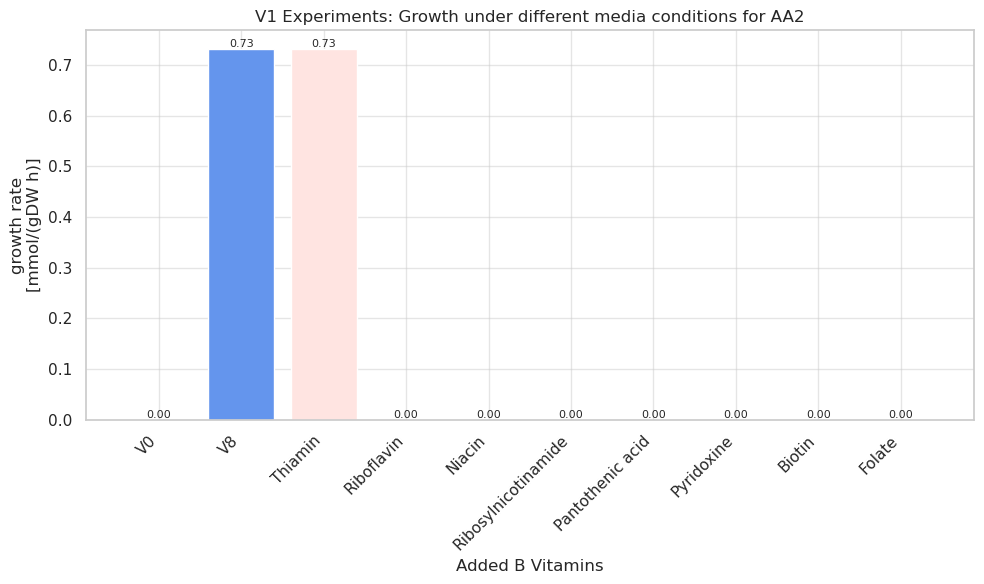

In [110]:
# V1 for Bbi with Alanine as carbon source (+ M9)
get_v1_growth(AA2, "V1", ala, EX_V8, EX_V8_names)

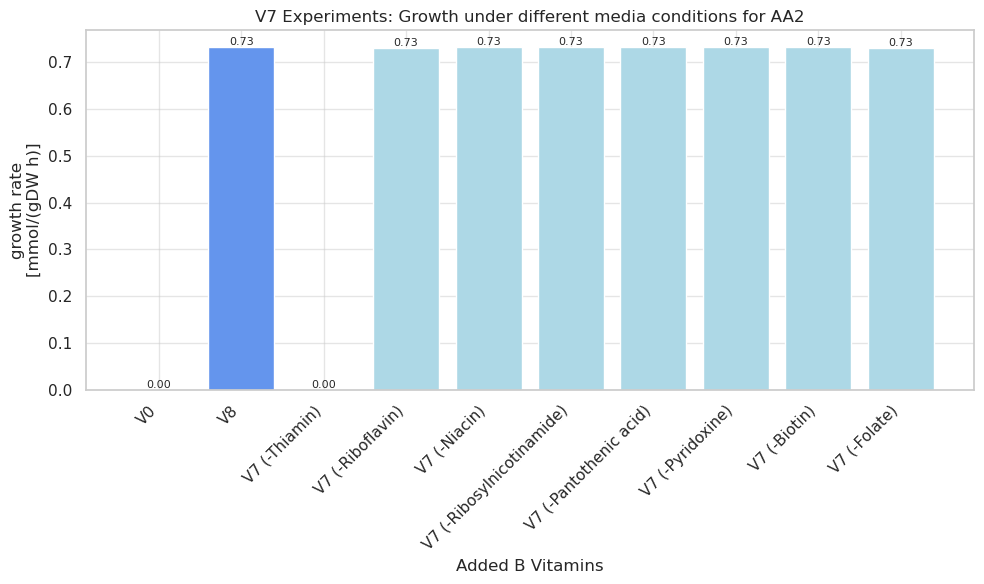

In [111]:
# V7 for Bbi with Alanine as carbon source (+ M9)
get_v7_growth(AA2, "V7", ala, EX_V8, EX_V8_names)

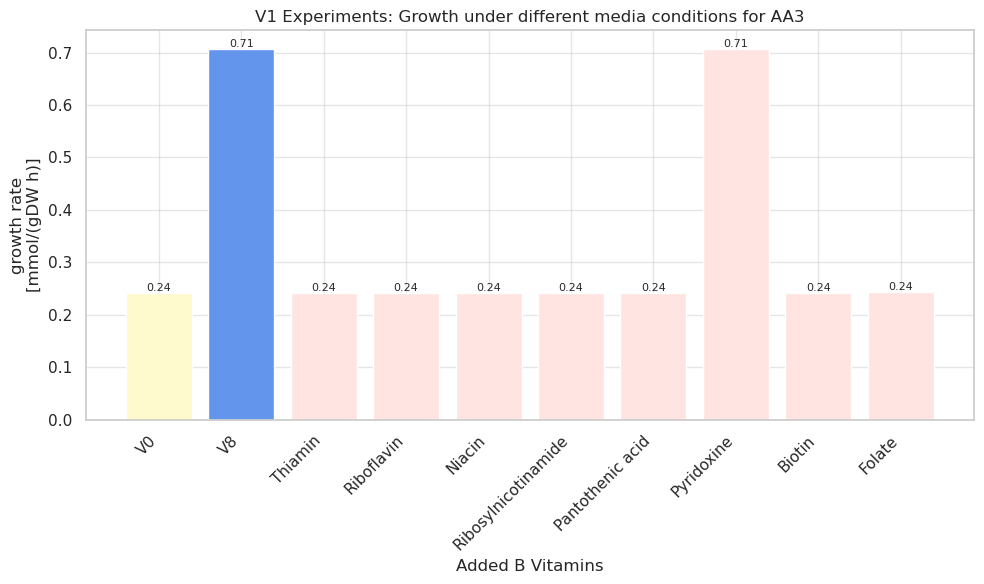

In [112]:
# V1 for Cpu with Glucose as carbon source (+ M9)
get_v1_growth(AA3, "V1", glu, EX_V8, EX_V8_names)

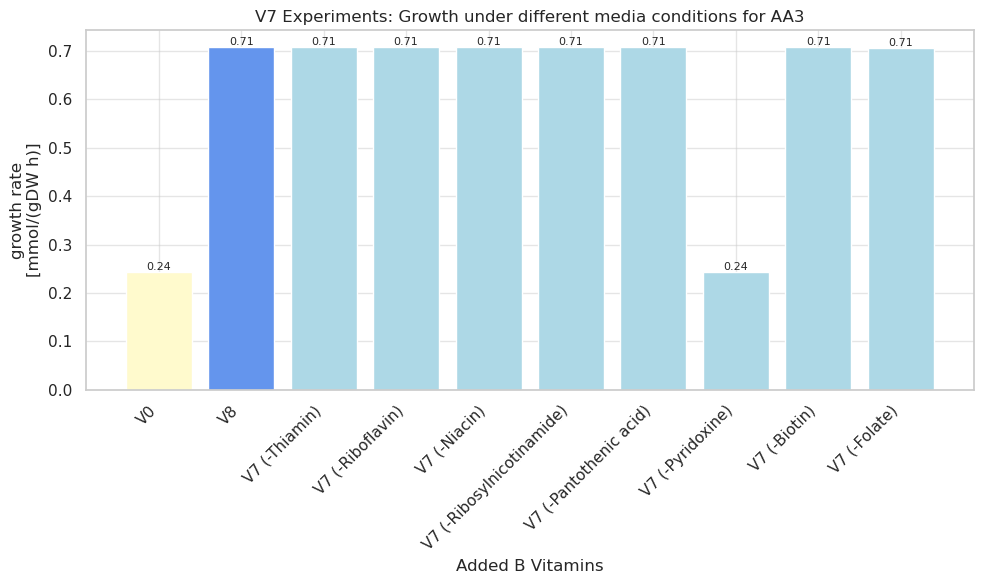

In [113]:
# V7 for Cpu with Glucose as carbon source (+ M9)
get_v7_growth(AA3, "V7", glu, EX_V8, EX_V8_names)

All Figures were saved as .svg and later edited by hand in Inkscape. This was done to improve readability, the visuals and the layout overall (this means colours and labels can be different in the paper than in here).

In [81]:
# Generate the DataFrame
df_vitamins = get_v1_v7_df(AA2, ala, EX_V8, EX_V8_names)

# Save to CSV matching the original format
# df_vitamins.to_csv("../Datasets/in_silico_data/Vitamins_V1-V7_Bpi.csv", index=False)